# Actividad 3.1.2 – Implementación técnica de un proyecto de ciencia de datos
**SCY1102 · EA3 Ejecución, monitoreo y control del proyecto · Caso 2: SaludConex**

**Notebook 2 de 2.** Usa el archivo `saludconex_reservas_2023_2025.csv` generado por `01_SaludConex_Generacion_Datos_Sinteticos.ipynb`.

**Objetivo del modelo (según el caso):** estimar la probabilidad de que una reserva médica termine en inasistencia, para usarla como **apoyo a la gestión** en acciones preventivas: recordatorios adicionales, confirmación anticipada, contacto telefónico, gestión de listas de espera y priorización administrativa. El modelo **no cancela ni niega horas**.

**Registro de cambios (v2.1 respecto de v2.0)**

| # | Cambio | Dónde |
|---|---|---|
| 1 | Edad y centro médico pasan por una prueba de necesidad con regla fijada antes de ver resultados (coherencia con RF2 del plan y con el sesgo etario del EP1). | Paso 5.1 |
| 2 | Regla de desempate explícita entre candidatos y lectura de la auditoría de equidad con acciones (RNF10). | Pasos 5.3 y 6 |
| 3 | La automatización es autónoma: el paquete del modelo guarda pipeline, calibrador, fondo SHAP, umbrales y acciones; el proceso corre desde un script en un proceso Python independiente. | Paso 8 |
| 4 | Explicaciones SHAP legibles para el personal (agrupadas por variable original) y un único fondo SHAP para todo el notebook. | Pasos 3, 7 y 8 |
| 5 | Reflexión grupal reformulada. | Final |
| 6 | Sección 6.1: mitigación de equidad con umbrales por grupo de edad (T12) y decisión del hito M03. | Paso 6.1 |

## Paso 1. Cargar el dataset del proyecto

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import unicodedata

# En Colab, si el CSV quedó en Drive:
# from google.colab import drive; drive.mount('/content/drive')
# RUTA = '/content/drive/MyDrive/saludconex_reservas_2023_2025.csv'
RUTA = 'saludconex_reservas_2023_2025.csv'
SEED = 42
SUCURSAL_PILOTO = 'Providencia'   # elección académica del plan (datos completos y volumen suficiente)
CAPACIDAD_DIARIA = 30             # supuesto de llamadas/día; debe validarlo Operaciones
FECHAS = ['fecha_solicitud', 'fecha_atencion', 'fecha_hora_atencion', 'fecha_hora_solicitud',
          'fecha_prediccion', 'fecha_cancelacion', 'fecha_confirmacion']
datos = pd.read_csv(RUTA, parse_dates=FECHAS)
print(f'Filas: {len(datos):,} | columnas: {datos.shape[1]}')
datos.info()

Filas: 1,536,727 | columnas: 23


<class 'pandas.DataFrame'>
RangeIndex: 1536727 entries, 0 to 1536726
Data columns (total 23 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   id_reserva                 1536727 non-null  str           
 1   id_paciente                1536727 non-null  str           
 2   edad                       1528119 non-null  float64       
 3   comuna                     1500835 non-null  str           
 4   centro_medico              1536727 non-null  str           
 5   especialidad               1536727 non-null  str           
 6   profesional                1536727 non-null  str           
 7   fecha_solicitud            1536727 non-null  datetime64[us]
 8   fecha_atencion             1536727 non-null  datetime64[us]
 9   horario_atencion           1536727 non-null  str           
 10  dias_anticipacion          1536727 non-null  int64         
 11  asistencias_anteriores     1536727 non-null  int

In [2]:
datos.head()

,id_reserva,id_paciente,edad,comuna,centro_medico,especialidad,profesional,fecha_solicitud,fecha_atencion,horario_atencion,...,inasistencias_anteriores,tipo_prevision,modalidad_atencion,confirmacion_recordatorio,resultado_reserva,fecha_hora_atencion,fecha_hora_solicitud,fecha_prediccion,fecha_cancelacion,fecha_confirmacion
0,RES-0000001,PAC-133812,27.0,pudahuel,Maipú,Ginecología,PRO-5302,2022-10-04,2023-01-02,11:20,...,0,FONASA B,Presencial,Confirmó,Asistió,2023-01-02 11:20:00,2022-10-04 10:50:00,2023-01-01 20:00:00,NaT,2023-01-01 11:50:00
1,RES-0000002,PAC-031837,19.0,El Bosque,San Bernardo,Cardiología,PRO-8501,2022-10-05,2023-01-03,16:00,...,0,FONASA D,Presencial,No aplica,Cancelada,2023-01-03 16:00:00,2022-10-05 15:30:00,2023-01-02 20:00:00,2023-01-01 16:00:00,NaT
2,RES-0000003,PAC-211133,73.0,La Florida,La Florida,Cardiología,PRO-6501,2022-10-05,2023-01-03,19:40,...,0,FONASA C,Telemedicina,Confirmó,Asistió,2023-01-03 19:40:00,2022-10-05 19:10:00,2023-01-02 20:00:00,NaT,2023-01-02 20:10:00
3,RES-0000004,PAC-008776,68.0,Las Condes,Las Condes,Cardiología,PRO-2501,2022-10-05,2023-01-03,10:40,...,0,ISAPRE,Presencial,No respondió,Asistió,2023-01-03 10:40:00,2022-10-05 10:10:00,2023-01-02 20:00:00,NaT,NaT
4,RES-0000005,PAC-114348,8.0,Las Condes,Santiago Centro,Dermatología,PRO-3602,2022-10-05,2023-01-03,08:00,...,0,FONASA D,Presencial,No aplica,Cancelada,2023-01-03 08:00:00,2022-10-05 07:30:00,2023-01-02 20:00:00,2023-01-01 08:00:00,NaT


In [3]:
datos.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id_reserva,1536727,1536012,RES-0000407,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id_paciente,1536727,191651,PAC-058633,114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,1528119.0,NaN,NaN,NaN,40.152908,0.0,20.0,39.0,58.0,92.0,24.035778
comuna,1500835,64,Puente Alto,183147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
centro_medico,1536727,8,Santiago Centro,310269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
especialidad,1536727,8,Medicina general,498532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
profesional,1536727,152,PRO-3101,20481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_solicitud,1536727,NaN,NaN,NaN,2024-06-21 01:11:00.720870,2022-10-04 00:00:00,2023-09-16 00:00:00,2024-06-20 00:00:00,2025-03-29 00:00:00,2025-12-31 00:00:00,NaN
fecha_atencion,1536727,NaN,NaN,NaN,2024-07-01 16:42:22.496619,2023-01-02 00:00:00,2023-09-27 00:00:00,2024-07-02 00:00:00,2025-04-09 00:00:00,2025-12-31 00:00:00,NaN
horario_atencion,1536727,36,10:20,48032,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Paso 2. Analizar las clases y generar gráficos representativos
La variable de resultado es `resultado_reserva`, con tres valores: *Asistió*, *No asistió* y *Cancelada*.

                   reservas      %
resultado_reserva                 
Asistió             1152901  75.02
No asistió           261331  17.01
Cancelada            122495   7.97


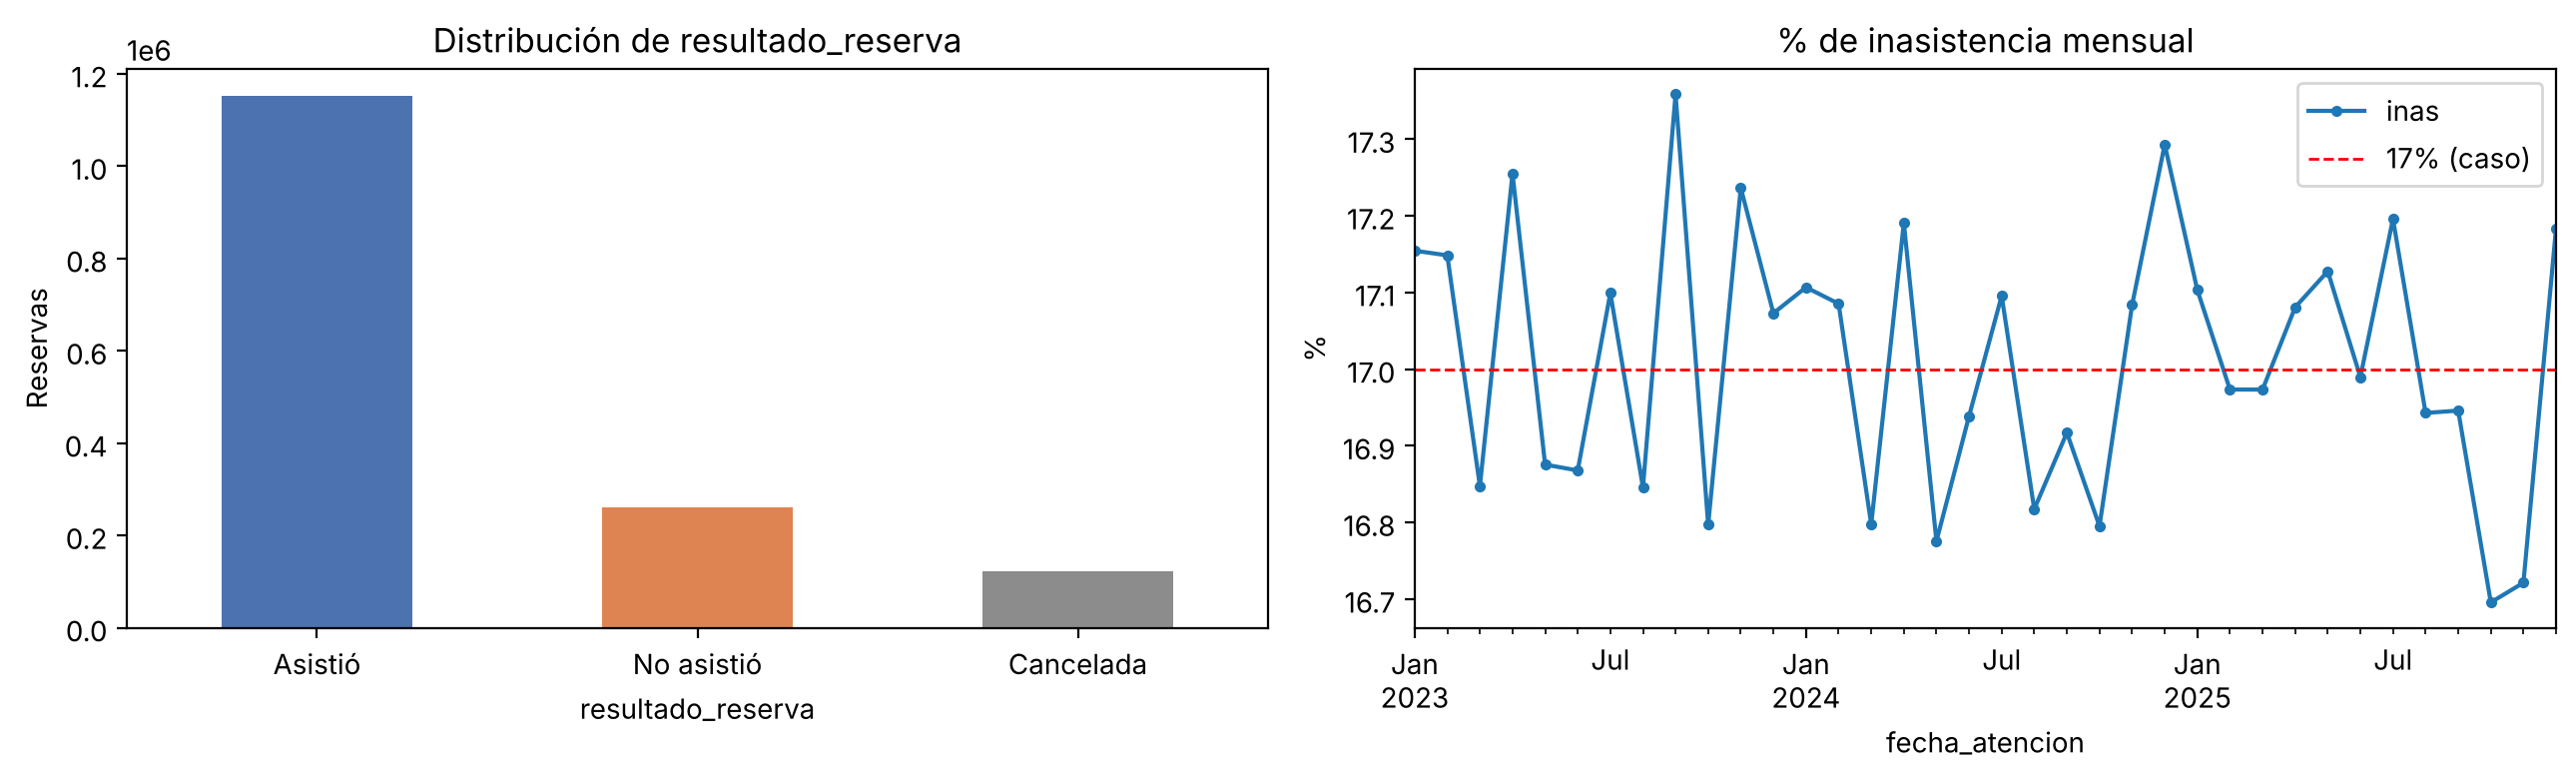

In [4]:
clases = datos['resultado_reserva'].value_counts()
print(pd.DataFrame({'reservas': clases, '%': (clases / len(datos) * 100).round(2)}))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
clases.plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452', '#8C8C8C'], rot=0)
ax[0].set_title('Distribución de resultado_reserva'); ax[0].set_ylabel('Reservas')
mensual = datos.assign(inas=datos.resultado_reserva.eq('No asistió')).groupby(
    datos.fecha_atencion.dt.to_period('M'))['inas'].mean() * 100
mensual.plot(ax=ax[1], marker='o', ms=3)
ax[1].axhline(17, color='red', ls='--', lw=1, label='17% (caso)')
ax[1].set_title('% de inasistencia mensual'); ax[1].set_ylabel('%'); ax[1].legend()
plt.tight_layout(); plt.show()

Las clases están desbalanceadas. La distribución anterior incluye las cancelaciones y usa todas las reservas como denominador. Después de excluir cancelaciones y reservas inexistentes al corte, se informará de nuevo la tasa del conjunto evaluable. La exactitud por sí sola puede ser alta aunque no se detecte ninguna inasistencia; por eso se complementa con precisión, recall, AUC-ROC y average precision.

Tasa entre reservas evaluables: 18.45%


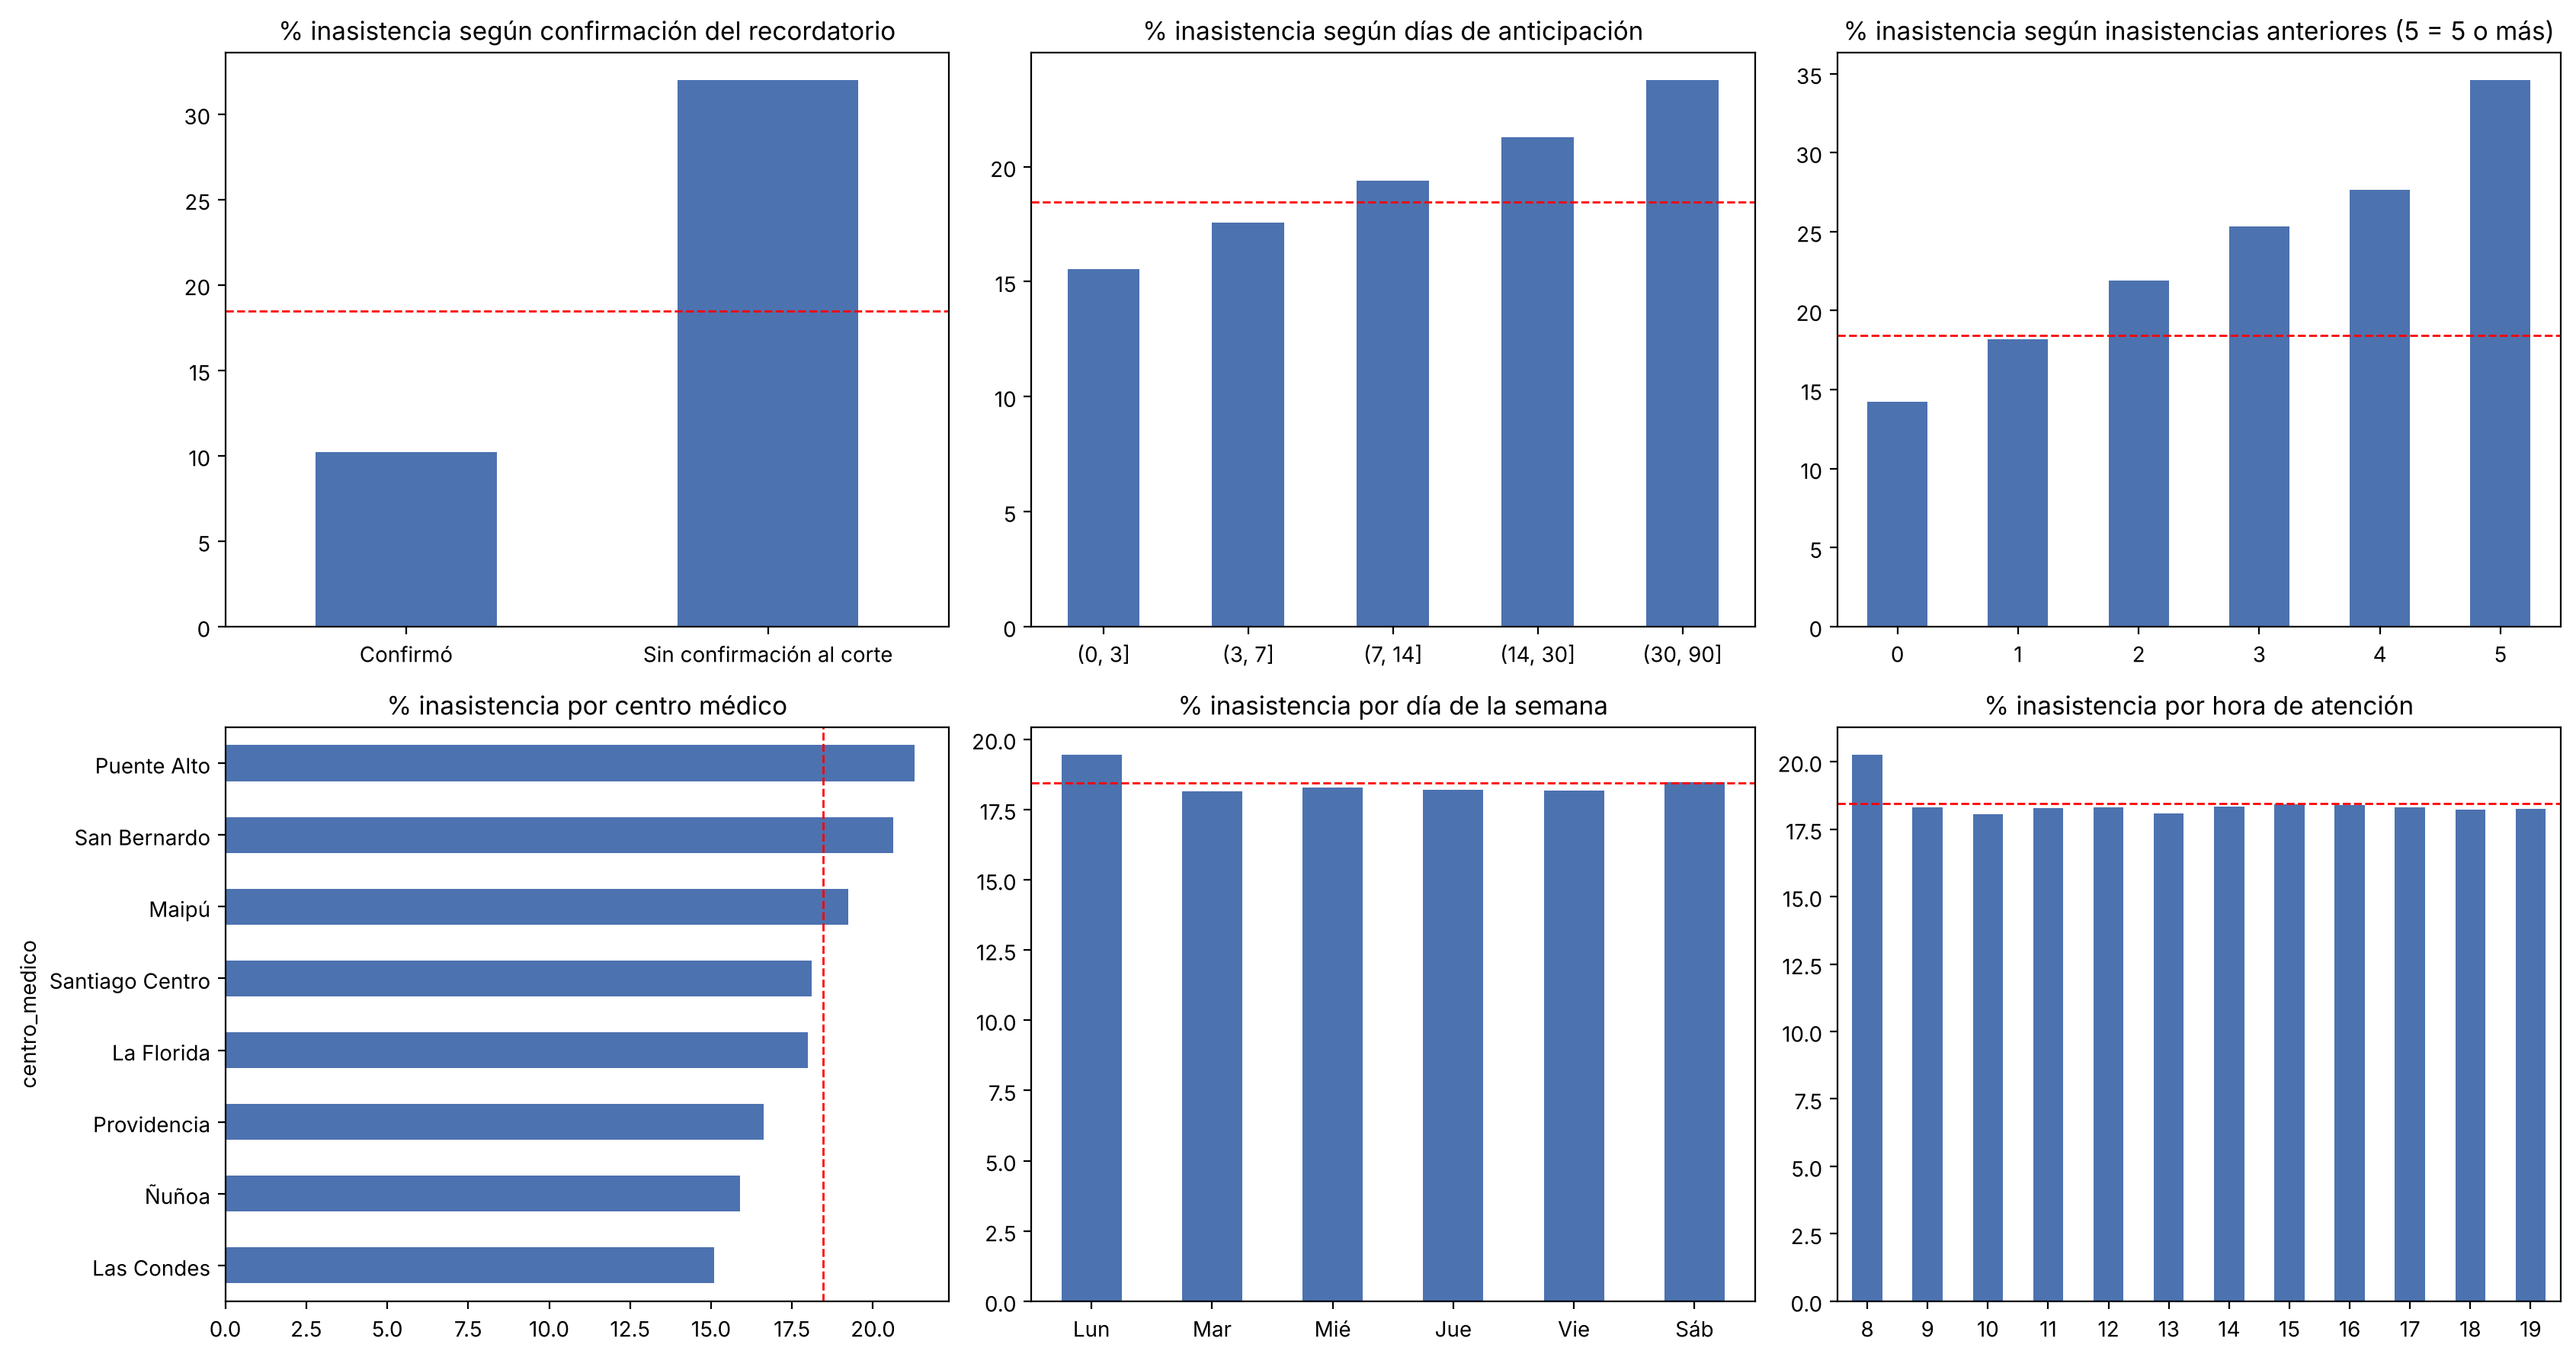

In [5]:
tmp = datos.drop_duplicates('id_reserva').copy()
tmp = tmp[tmp.fecha_hora_solicitud.le(tmp.fecha_prediccion) & tmp.fecha_cancelacion.isna()].copy()
tmp['inasistencia'] = tmp.resultado_reserva.eq('No asistió')
confirmada_al_corte = tmp.fecha_confirmacion.notna() & tmp.fecha_confirmacion.le(tmp.fecha_prediccion)
tmp['confirmacion_recordatorio'] = np.where(confirmada_al_corte, 'Confirmó', 'Sin confirmación al corte')
referencia_evaluable = tmp['inasistencia'].mean() * 100
print(f'Tasa entre reservas evaluables: {referencia_evaluable:.2f}%')
fig, ax = plt.subplots(2, 3, figsize=(17, 9))

(tmp.groupby('confirmacion_recordatorio')['inasistencia'].mean() * 100).plot.bar(ax=ax[0, 0], rot=0, color='#4C72B0')
ax[0, 0].set_title('% inasistencia según confirmación del recordatorio')

(tmp.groupby(pd.cut(tmp.dias_anticipacion, [-1, 0, 3, 7, 14, 30, 90]), observed=True)['inasistencia'].mean() * 100
 ).plot.bar(ax=ax[0, 1], rot=0, color='#4C72B0')
ax[0, 1].set_title('% inasistencia según días de anticipación')

(tmp.groupby(tmp.inasistencias_anteriores.clip(upper=5))['inasistencia'].mean() * 100).plot.bar(ax=ax[0, 2], rot=0, color='#4C72B0')
ax[0, 2].set_title('% inasistencia según inasistencias anteriores (5 = 5 o más)')

(tmp.groupby('centro_medico')['inasistencia'].mean().sort_values() * 100).plot.barh(ax=ax[1, 0], color='#4C72B0')
ax[1, 0].set_title('% inasistencia por centro médico')

(tmp.groupby(tmp.fecha_atencion.dt.dayofweek)['inasistencia'].mean() * 100).rename(
    index=dict(enumerate(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb']))).plot.bar(ax=ax[1, 1], rot=0, color='#4C72B0')
ax[1, 1].set_title('% inasistencia por día de la semana')

(tmp.groupby(tmp.horario_atencion.str[:2].astype(int))['inasistencia'].mean() * 100).plot.bar(ax=ax[1, 2], rot=0, color='#4C72B0')
ax[1, 2].set_title('% inasistencia por hora de atención')
for a in ax.flat:
    a.axhline(referencia_evaluable, color='red', ls='--', lw=1) if a not in [ax[1, 0]] else a.axvline(referencia_evaluable, color='red', ls='--', lw=1)
    a.set_xlabel('')
plt.tight_layout(); plt.show()

In [6]:
# Calidad de datos: nulos por centro (problema de migración mencionado en el caso)
nulos = datos.isna().groupby(datos.centro_medico).mean()[['edad', 'comuna', 'tipo_prevision', 'confirmacion_recordatorio']] * 100
print('% de nulos por centro:'); display(nulos.round(2))
print('Registros duplicados:', datos.duplicated().sum())
print('Comunas distintas (con formatos inconsistentes):', datos.comuna.nunique())

% de nulos por centro:


,edad,comuna,tipo_prevision,confirmacion_recordatorio
centro_medico,,,,
La Florida,0.00,0.00,0.00,0.00
Las Condes,0.00,0.00,0.00,0.00
Maipú,2.02,8.36,6.02,4.04
Providencia,0.00,0.00,0.00,0.00
Puente Alto,0.00,0.00,0.00,0.00
San Bernardo,1.97,8.33,6.07,3.94
Santiago Centro,0.00,0.00,0.00,0.00
Ñuñoa,0.00,0.00,0.00,0.00


Registros duplicados: 715
Comunas distintas (con formatos inconsistentes): 64


## Paso 3. Preparar los datos y seleccionar variables dependiente e independientes

1. Eliminar duplicados por `id_reserva`.
2. Usar solo reservas existentes y vigentes al corte de las 20:00 del día anterior. La vigencia se comprueba con marcas de cancelación conocidas, no con el resultado futuro. En este simulador no hay cancelaciones tardías.
3. Normalizar comunas con una regla determinista, exclusivamente para auditoría.
4. Imputar y codificar dentro del pipeline, ajustando solo con entrenamiento.
5. Construir variables derivadas del agendamiento y del historial disponible al corte.

**Dependiente:** `inasistencia` = 1 para No asistió, 0 para Asistió. El resultado final sirve como etiqueta retrospectiva, nunca como entrada de inferencia.

**Independientes candidatas:** variables de agendamiento e historial, como define el RF2 del plan (especialidad, anticipación, historial y confirmaciones). Se excluyen identificadores, profesional, fechas completas, comuna, previsión y datos clínicos.

**Variables sensibles en prueba:** `edad` (el EP1 identificó un sesgo etario) y `centro_medico` (la sede funciona en parte como sustituto territorial de la comuna). Ninguna de las dos está listada en el RF2, por lo que solo se mantienen si superan la prueba de necesidad del Paso 5.1. Edad, comuna y sede se conservan siempre para auditoría; excluir variables no garantiza equidad.

**Momento de uso:** cada día a las 20:00 para las citas del día siguiente. Solo se utiliza la confirmación registrada hasta ese instante. Los antecedentes también deben estar calculados a ese corte.

**Limitación del corte:** las citas de las 19:40 reciben la respuesta al recordatorio a las 20:10, después del corte, por lo que nunca aparecen como confirmadas. En producción se resolvería adelantando el recordatorio o el corte; aquí se declara como artefacto del calendario simulado.

In [7]:
def normalizar_texto(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    return s.strip().lower()

base = datos.drop_duplicates('id_reserva').copy()
print('Duplicados eliminados:', len(datos) - len(base))
existente = base.fecha_hora_solicitud.le(base.fecha_prediccion)
cancelada_al_corte = base.fecha_cancelacion.notna() & base.fecha_cancelacion.le(base.fecha_prediccion)
df = base[existente & ~cancelada_al_corte].copy()
assert not df.resultado_reserva.eq('Cancelada').any(), 'Revisar política de cancelaciones tardías'
df['comuna'] = df['comuna'].map(lambda c: normalizar_texto(c) if pd.notna(c) else np.nan)
conf_al_corte = df.fecha_confirmacion.notna() & df.fecha_confirmacion.le(df.fecha_prediccion)
# Un registro migrado sin dato se conserva como desconocido para imputación.
df['confirmacion_recordatorio'] = np.where(conf_al_corte, 'Confirmó', 'Sin confirmación al corte').astype(object)
df.loc[base.loc[df.index, 'confirmacion_recordatorio'].isna(), 'confirmacion_recordatorio'] = np.nan
print(f'Reservas evaluables: {len(df):,}; excluidas por creación posterior: {(~existente).sum():,}')
print(f'Inasistencia en evaluables: {df.resultado_reserva.eq("No asistió").mean():.2%}')
print('Comunas normalizadas:', df.comuna.nunique())

Duplicados eliminados: 715


Reservas evaluables: 1,224,104; excluidas por creación posterior: 189,467
Inasistencia en evaluables: 18.45%
Comunas normalizadas: 20


### Funciones compartidas
Las funciones que transforman datos, calculan probabilidades y generan explicaciones se escriben en un módulo (`saludconex_variables.py`). El entrenamiento, las predicciones del Paso 7 y la automatización del Paso 8 usan **exactamente el mismo código**, y el script de automatización no depende de variables que solo existen en la memoria de este notebook.

Las explicaciones SHAP se agrupan por **variable original** (por ejemplo, todas las columnas one-hot de `especialidad` suman una sola contribución) y se redactan para el personal administrativo, cumpliendo el RNF5 de usabilidad.

In [8]:
%%writefile saludconex_variables.py
"""Funciones compartidas por el entrenamiento, las predicciones nuevas y la automatización de SaludConex."""
import numpy as np
import pandas as pd
from scipy.special import logit

ETIQUETAS = {
    'edad': 'Edad', 'dias_anticipacion': 'Días entre reserva y cita',
    'asistencias_anteriores': 'Asistencias anteriores', 'inasistencias_anteriores': 'Inasistencias anteriores',
    'cancelaciones_anteriores': 'Cancelaciones anteriores', 'reservas_previas': 'Reservas previas',
    'tasa_inasistencia_hist': 'Tasa histórica de inasistencia', 'hora_atencion': 'Hora de la cita',
    'dia_semana': 'Día de la cita', 'mes': 'Mes de la cita', 'centro_medico': 'Centro',
    'especialidad': 'Especialidad', 'modalidad_atencion': 'Modalidad',
    'confirmacion_recordatorio': 'Recordatorio'}
DIAS = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo']


def crear_variables(d):
    """Variables derivadas. Se usa igual para entrenamiento, nuevas predicciones y la automatización."""
    d = d.copy()
    d['hora_atencion'] = d['horario_atencion'].astype(str).str[:2].astype(int)
    d['dia_semana'] = d['fecha_atencion'].dt.dayofweek
    d['mes'] = d['fecha_atencion'].dt.month
    d['reservas_previas'] = d['asistencias_anteriores'] + d['inasistencias_anteriores'] + d['cancelaciones_anteriores']
    atendidas = d['asistencias_anteriores'] + d['inasistencias_anteriores']
    d['tasa_inasistencia_hist'] = np.where(atendidas > 0, d['inasistencias_anteriores'] / atendidas.where(atendidas > 0, 1), 0)
    return d


def preparar_reservas(d, fecha_proceso):
    """Construye la foto conocida al corte; el historial de entrada debe corresponder a ese corte."""
    d = d.drop_duplicates('id_reserva').copy()
    corte = pd.Timestamp(fecha_proceso)
    for c in ['fecha_atencion', 'fecha_solicitud', 'fecha_hora_solicitud', 'fecha_cancelacion',
              'fecha_confirmacion', 'fecha_prediccion']:
        d[c] = pd.to_datetime(d[c])
    activa = d.fecha_cancelacion.isna() | d.fecha_cancelacion.gt(corte)
    d = d[d.fecha_hora_solicitud.le(corte) & activa].copy()
    # No aceptar antecedentes calculados para otro instante.
    if not d.empty and not d.fecha_prediccion.eq(corte).all():
        raise ValueError('El historial debe calcularse al corte exacto de esta ejecución')
    conf = d.fecha_confirmacion.notna() & d.fecha_confirmacion.le(corte)
    falta = d.confirmacion_recordatorio.isna()
    d['confirmacion_recordatorio'] = pd.Series(np.where(conf, 'Confirmó', 'Sin confirmación al corte'),
                                               index=d.index, dtype=object)
    d.loc[falta, 'confirmacion_recordatorio'] = np.nan
    return crear_variables(d)


def variables_modelo(paquete):
    return paquete['variables_numericas'] + paquete['variables_categoricas']


def probabilidad(paquete, X):
    """Probabilidad calibrada de inasistencia con el pipeline y el calibrador del paquete."""
    p = paquete['pipeline'].predict_proba(X)[:, 1]
    if paquete.get('calibrador') is not None:
        p = paquete['calibrador'].predict_proba(logit(np.clip(p, 1e-6, 1 - 1e-6)).reshape(-1, 1))[:, 1]
    return p


def nivel_riesgo(paquete, p):
    p = np.asarray(p)
    return np.where(p >= paquete['umbral_alto'], 'Alto', np.where(p >= paquete['umbral_medio'], 'Medio', 'Bajo'))


def _denso(z):
    return z.toarray() if hasattr(z, 'toarray') else np.asarray(z)


def _grupos_columnas(paquete):
    """Índices de las columnas transformadas que pertenecen a cada variable original."""
    nombres = list(paquete['pipeline'].named_steps['prep'].get_feature_names_out())
    grupos = {}
    for v in paquete['variables_numericas']:
        grupos[v] = [nombres.index(f'num__{v}')]
    for v in paquete['variables_categoricas']:
        if f'cat__{v}' in nombres:                       # codificación ordinal: una columna
            grupos[v] = [nombres.index(f'cat__{v}')]
        else:                                            # one-hot: varias columnas
            grupos[v] = [i for i, n in enumerate(nombres) if n.startswith(f'cat__{v}_')]
    return grupos


def _formato(var, valor):
    if pd.isna(valor):
        return 'sin dato'
    if var == 'tasa_inasistencia_hist':
        return f'{valor:.0%}'
    if var == 'dia_semana':
        return DIAS[int(valor)]
    if var == 'hora_atencion':
        return f'{int(valor):02d}:00'
    if isinstance(valor, (int, float, np.integer, np.floating)):
        return str(int(valor)) if float(valor).is_integer() else f'{valor:.1f}'
    return str(valor)


def crear_explicador(paquete):
    """Explicador SHAP construido solo con el contenido del paquete (mismo fondo en todo el proyecto)."""
    import shap
    estimador = paquete['pipeline'].named_steps['modelo']
    fondo = paquete['fondo_shap']
    if paquete['algoritmo'] == 'Regresión logística':
        return shap.LinearExplainer(estimador, fondo)
    return shap.PermutationExplainer(estimador.decision_function,
                                     shap.maskers.Independent(fondo, max_samples=len(fondo)),
                                     seed=paquete['semilla'])


def explicar(paquete, d, explicador=None, top=3):
    """Devuelve (textos legibles, contribuciones por variable original, valor base).

    Las contribuciones están en log-odds del score bruto (antes de calibrar): indican
    qué factores empujan el riesgo hacia arriba o hacia abajo, no efectos causales.
    """
    explicador = explicador or crear_explicador(paquete)
    preprocesador = paquete['pipeline'].named_steps['prep']
    estimador = paquete['pipeline'].named_steps['modelo']
    z = _denso(preprocesador.transform(d[variables_modelo(paquete)]))
    if paquete['algoritmo'] == 'Regresión logística':
        valores = np.asarray(explicador.shap_values(z))
        base = float(np.ravel(explicador.expected_value)[0])
    else:
        e = explicador(z, max_evals=5 * (2 * z.shape[1] + 1), silent=True)
        valores, base = np.asarray(e.values), float(np.ravel(e.base_values)[0])
    assert np.allclose(base + valores.sum(axis=1), estimador.decision_function(z), atol=1e-4), 'Revisar suma de SHAP'
    grupos = _grupos_columnas(paquete)
    agregados = pd.DataFrame({v: valores[:, idx].sum(axis=1) for v, idx in grupos.items()}, index=d.index)
    textos = []
    for k, (_, fila) in enumerate(agregados.iterrows()):
        partes = []
        for v in fila.abs().sort_values(ascending=False).index[:top]:
            flecha = '↑ riesgo' if fila[v] > 0 else '↓ riesgo'
            partes.append(f'{ETIQUETAS.get(v, v)}: {_formato(v, d[v].iloc[k])} ({flecha})')
        textos.append('; '.join(partes))
    return textos, agregados, base

Overwriting saludconex_variables.py


In [9]:
import importlib
import saludconex_variables as sv
importlib.reload(sv)

df = sv.crear_variables(df)
df['inasistencia'] = (df['resultado_reserva'] == 'No asistió').astype(int)

VAR_NUMERICAS_CANDIDATAS = ['edad', 'dias_anticipacion', 'asistencias_anteriores', 'inasistencias_anteriores',
                            'cancelaciones_anteriores', 'reservas_previas', 'tasa_inasistencia_hist',
                            'hora_atencion', 'dia_semana', 'mes']
VAR_CATEGORICAS_CANDIDATAS = ['centro_medico', 'especialidad', 'modalidad_atencion', 'confirmacion_recordatorio']
VARIABLES_SENSIBLES = ['edad', 'centro_medico']     # se someten a la prueba de necesidad del Paso 5.1
OBJETIVO = 'inasistencia'

print('Variable dependiente:', OBJETIVO)
print('Independientes candidatas:', VAR_NUMERICAS_CANDIDATAS + VAR_CATEGORICAS_CANDIDATAS)
print('En prueba de necesidad:', VARIABLES_SENSIBLES)
assert not {'comuna', 'tipo_prevision', 'id_paciente', 'resultado_reserva'} & set(
    VAR_NUMERICAS_CANDIDATAS + VAR_CATEGORICAS_CANDIDATAS)

Variable dependiente: inasistencia
Independientes candidatas: ['edad', 'dias_anticipacion', 'asistencias_anteriores', 'inasistencias_anteriores', 'cancelaciones_anteriores', 'reservas_previas', 'tasa_inasistencia_hist', 'hora_atencion', 'dia_semana', 'mes', 'centro_medico', 'especialidad', 'modalidad_atencion', 'confirmacion_recordatorio']
En prueba de necesidad: ['edad', 'centro_medico']


## Paso 4. Separar los datos en conjuntos de entrenamiento y test
Se utiliza separación temporal con dos ventanas de validación: entrenamiento (2023–junio 2024), selección de modelo y de variables (julio–septiembre 2024), calibración y umbrales (octubre–diciembre 2024), y test final (2025). El test no interviene en la selección ni en el ajuste. Los conjuntos se separan por `fecha_prediccion`, que es el momento en que se habría emitido cada score. Se deja un margen de dos días al final de cada ventana previa para que sus resultados ya estén resueltos al iniciar la siguiente.

In [10]:
# Separar por momento de predicción y dejar una purga temporal de dos días.
f = df.fecha_prediccion
lim1, lim2, lim3 = map(pd.Timestamp, ['2024-07-01', '2024-10-01', '2025-01-01'])
purga = pd.Timedelta(days=2)
train = df[f < lim1 - purga].copy()
valid_modelo = df[(f >= lim1) & (f < lim2 - purga)].copy()
valid_calibracion = df[(f >= lim2) & (f < lim3 - purga)].copy()
test = df[f >= lim3].copy()
resumen = pd.DataFrame([{'conjunto': nombre, 'filas': len(d),
    '% inasistencia': d[OBJETIVO].mean()*100,
    'desde': d.fecha_prediccion.min(), 'hasta': d.fecha_prediccion.max()}
    for nombre, d in [('Entrenamiento',train), ('Validación selección',valid_modelo),
                     ('Validación calibración',valid_calibracion), ('Test final',test)]])
assert train.fecha_prediccion.max() < valid_modelo.fecha_prediccion.min()
assert valid_modelo.fecha_prediccion.max() < valid_calibracion.fecha_prediccion.min()
assert valid_calibracion.fecha_prediccion.max() < test.fecha_prediccion.min()
display(resumen)

,conjunto,filas,% inasistencia,desde,hasta
0,Entrenamiento,609644,18.460446,2023-01-01 20:00:00,2024-06-28 20:00:00
1,Validación selección,105789,18.345953,2024-07-01 20:00:00,2024-09-27 20:00:00
2,Validación calibración,94894,18.494320,2024-10-01 20:00:00,2024-12-29 20:00:00
3,Test final,406821,18.447917,2025-01-01 20:00:00,2025-12-30 20:00:00


## Paso 5. Entrenar el modelo

### 5.1 Prueba de necesidad de las variables sensibles
**Regla fijada antes de ver resultados:** una variable sensible se excluye si quitarla reduce la AUC de validación en **menos de 0,01**. Es decir, solo se mantiene si aporta capacidad predictiva relevante; si no, prima la minimización de datos y la reducción del riesgo de sesgo. La prueba se hace con la regresión logística de referencia, en orden (primero edad y luego centro médico), usando solo la ventana de validación de selección.

In [11]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import time


def prep_logistica(num, cat):
    return ColumnTransformer([
        ('num', Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]), num),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Desconocido')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat)])


def prep_arboles(num, cat):
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num),
        ('cat', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Desconocido')),
                          ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))]), cat)])


def logistica(num, cat):
    return Pipeline([('prep', prep_logistica(num, cat)),
                     ('modelo', LogisticRegression(max_iter=1000, class_weight='balanced'))])


def auc_validacion(num, cat):
    m = logistica(num, cat).fit(train[num + cat], train[OBJETIVO])
    return roc_auc_score(valid_modelo[OBJETIVO], m.predict_proba(valid_modelo[num + cat])[:, 1])


PERDIDA_MAXIMA = 0.01
num, cat = list(VAR_NUMERICAS_CANDIDATAS), list(VAR_CATEGORICAS_CANDIDATAS)
auc_actual = auc_validacion(num, cat)
filas = [{'prueba': 'Todas las candidatas', 'AUC validación': auc_actual, 'pérdida al quitar': np.nan, 'decisión': '—'}]
VARIABLES_EXCLUIDAS = []
for v in VARIABLES_SENSIBLES:
    num_sin, cat_sin = [x for x in num if x != v], [x for x in cat if x != v]
    auc_sin = auc_validacion(num_sin, cat_sin)
    perdida = auc_actual - auc_sin
    excluir = perdida < PERDIDA_MAXIMA
    filas.append({'prueba': f'Sin {v}', 'AUC validación': auc_sin, 'pérdida al quitar': perdida,
                  'decisión': 'Se excluye' if excluir else 'Se mantiene'})
    if excluir:
        num, cat, auc_actual = num_sin, cat_sin, auc_sin
        VARIABLES_EXCLUIDAS.append(v)

VAR_NUMERICAS, VAR_CATEGORICAS = num, cat
VARIABLES = VAR_NUMERICAS + VAR_CATEGORICAS
display(pd.DataFrame(filas).round(4))
print('Variables excluidas por la prueba:', VARIABLES_EXCLUIDAS)
print('Variables finales del modelo:', VARIABLES)

,prueba,AUC validación,pérdida al quitar,decisión
0,Todas las candidatas,0.7406,NaN,—
1,Sin edad,0.7393,0.0013,Se excluye
2,Sin centro_medico,0.7382,0.0011,Se excluye


Variables excluidas por la prueba: ['edad', 'centro_medico']
Variables finales del modelo: ['dias_anticipacion', 'asistencias_anteriores', 'inasistencias_anteriores', 'cancelaciones_anteriores', 'reservas_previas', 'tasa_inasistencia_hist', 'hora_atencion', 'dia_semana', 'mes', 'especialidad', 'modalidad_atencion', 'confirmacion_recordatorio']


**Lectura de la prueba.** Quitar la edad reduce la AUC de validación en solo 0,0013, y quitar luego el centro médico la reduce en 0,0011, ambas muy por debajo del límite de 0,01. Por la regla fijada de antemano, **las dos variables se excluyen**: en conjunto cuestan 0,0024 de AUC (de 0,7406 a 0,7382), una pérdida irrelevante frente al beneficio de no usar la edad como predictor (sesgo etario identificado en el EP1) ni la sede como sustituto territorial.

Con esto el modelo queda **alineado con el RF2 del plan**: usa solo variables de agendamiento, historial y confirmación. La edad, la comuna y la sede siguen disponibles, pero únicamente para la auditoría de equidad y para filtrar la sucursal piloto.

### 5.2 Entrenamiento de candidatos
Se comparan regresión logística y Histogram Gradient Boosting con un Dummy de referencia, con las variables finales del Paso 5.1. La imputación, el escalado y la codificación se ajustan solo con entrenamiento.

Los candidatos utilizan ponderación balanceada, por lo que sus scores iniciales no son probabilidades calibradas. Se selecciona con la primera ventana de validación y se ajusta una calibración sigmoide con la segunda. La política de contactos se define sin consultar el test.

Histogram Gradient Boosting es una adaptación académica del candidato LightGBM del plan; no se afirma que ambos algoritmos sean idénticos.

In [12]:
X_train, y_train = train[VARIABLES], train[OBJETIVO]
X_valid, y_valid = valid_modelo[VARIABLES], valid_modelo[OBJETIVO]
X_cal, y_cal = valid_calibracion[VARIABLES], valid_calibracion[OBJETIVO]
X_test, y_test = test[VARIABLES], test[OBJETIVO]

idx_cat = list(range(len(VAR_NUMERICAS), len(VARIABLES)))
modelos = {
    'Dummy (línea base)': Pipeline([('prep', prep_arboles(VAR_NUMERICAS, VAR_CATEGORICAS)),
                                    ('modelo', DummyClassifier(strategy='prior'))]),
    'Regresión logística': logistica(VAR_NUMERICAS, VAR_CATEGORICAS),
    'Gradient Boosting': Pipeline([('prep', prep_arboles(VAR_NUMERICAS, VAR_CATEGORICAS)),
                                   ('modelo', HistGradientBoostingClassifier(categorical_features=idx_cat, max_iter=300,
                                                                             learning_rate=0.1, class_weight='balanced',
                                                                             early_stopping=False, random_state=SEED))]),
}
for nombre, m in modelos.items():
    t0 = time.time(); m.fit(X_train, y_train)
    print(f'{nombre:22s} entrenado en {time.time() - t0:5.1f} s')

Dummy (línea base)     entrenado en   0.7 s


Regresión logística    entrenado en   1.7 s


Gradient Boosting      entrenado en   7.7 s


### 5.3 ¿Fueron suficientes los pasos anteriores? Selección y calibración
Se comparan AUC de entrenamiento y validación para detectar sobreajuste. Una brecha pequeña no demuestra ausencia de sobreajuste y los datos sintéticos no permiten concluir utilidad real.

**Regla de selección fijada de antemano:** se elige el candidato con mayor AUC de validación; si la diferencia entre ambos es **menor a 0,005**, se considera empate y se elige la regresión logística, por ser más simple, más estable y más fácil de explicar al personal (exigencia de trazabilidad del caso). El test se reserva para el Paso 6.

In [13]:
from scipy.special import logit

diag = []
for nombre, m in modelos.items():
    diag.append({'modelo': nombre, 'AUC entrenamiento': roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]),
                 'AUC validación': roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]),
                 'AP validación': average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])})
diag = pd.DataFrame(diag).set_index('modelo')
diag['diferencia'] = diag['AUC entrenamiento'] - diag['AUC validación']
display(diag.round(4))

TOLERANCIA_EMPATE = 0.005
auc_rl, auc_gb = diag.loc['Regresión logística', 'AUC validación'], diag.loc['Gradient Boosting', 'AUC validación']
if auc_gb - auc_rl >= TOLERANCIA_EMPATE:
    MEJOR, motivo = 'Gradient Boosting', 'supera a la regresión logística por al menos 0,005 de AUC'
elif auc_rl - auc_gb >= TOLERANCIA_EMPATE:
    MEJOR, motivo = 'Regresión logística', 'supera al Gradient Boosting por al menos 0,005 de AUC'
else:
    MEJOR, motivo = 'Regresión logística', f'empate técnico (diferencia {abs(auc_gb - auc_rl):.4f} < 0,005): se prefiere el modelo más simple e interpretable'
modelo_final = modelos[MEJOR]
print(f'Seleccionado: {MEJOR} -> {motivo}')

# Calibración independiente del entrenamiento y de la selección de candidato.
raw_cal = modelo_final.predict_proba(X_cal)[:, 1]
calibrador = LogisticRegression(C=1e6, max_iter=1000)
calibrador.fit(logit(np.clip(raw_cal, 1e-6, 1 - 1e-6)).reshape(-1, 1), y_cal)

# Fondo SHAP único (100 reservas de entrenamiento), guardado en el paquete y reutilizado en todo el notebook.
fondo_shap = sv._denso(modelo_final.named_steps['prep'].transform(X_train.sample(100, random_state=SEED)))

ACCIONES = {'Alto': 'Priorizar llamada humana y solicitar confirmación, sin alterar la reserva',
            'Medio': 'Contacto preventivo por canal institucional autorizado antes de la cita',
            'Bajo': 'Mantener recordatorio habitual; sin contacto adicional por el score'}

paquete = {'pipeline': modelo_final, 'calibrador': calibrador, 'algoritmo': MEJOR,
           'variables_numericas': VAR_NUMERICAS, 'variables_categoricas': VAR_CATEGORICAS,
           'fondo_shap': fondo_shap, 'acciones': ACCIONES, 'semilla': SEED}
prob_cal = sv.probabilidad(paquete, X_cal)
paquete['umbral_alto'] = UMBRAL_ALTO = float(np.quantile(prob_cal, 0.90))
paquete['umbral_medio'] = UMBRAL_MEDIO = float(np.quantile(prob_cal, 0.70))
print(f'Umbrales fijados con la ventana de calibración: alto = {UMBRAL_ALTO:.4f} | medio = {UMBRAL_MEDIO:.4f}')

,AUC entrenamiento,AUC validación,AP validación,diferencia
modelo,,,,
Dummy (línea base),0.5000,0.5000,0.1835,0.0000
Regresión logística,0.7217,0.7382,0.3956,-0.0165
Gradient Boosting,0.7373,0.7375,0.3961,-0.0003


Seleccionado: Regresión logística -> empate técnico (diferencia 0.0006 < 0,005): se prefiere el modelo más simple e interpretable
Umbrales fijados con la ventana de calibración: alto = 0.3716 | medio = 0.2349


**Lectura.** No hay señales de sobreajuste: la regresión logística incluso rinde levemente mejor en validación que en entrenamiento, y el Gradient Boosting tiene la misma AUC en ambos conjuntos. La diferencia entre candidatos es de 0,0006, muy por debajo de la tolerancia de 0,005, por lo que se aplica la regla de desempate y se selecciona la **regresión logística**.

Esto tiene una consecuencia para el plan: el RNF10 pedía que el candidato (LightGBM, aquí Gradient Boosting) superara a la regresión logística de referencia, y no la supera. La decisión documentada en H03 es mantener el modelo de referencia, que además es el más fácil de explicar al personal.

## Paso 6. Evaluar los resultados con métricas de desempeño

In [14]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, accuracy_score, brier_score_loss,
    RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import calibration_curve

filas = []
probabilidades_test = {}
for nombre, m in modelos.items():
    # El seleccionado usa su calibración; los demás conservan scores brutos.
    p = sv.probabilidad(paquete, X_test) if nombre == MEJOR else m.predict_proba(X_test)[:, 1]
    probabilidades_test[nombre] = p
    pred = p >= 0.5
    filas.append({'modelo': nombre, 'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred), 'f1': f1_score(y_test, pred, zero_division=0),
        'AUC-ROC': roc_auc_score(y_test, p), 'AP': average_precision_score(y_test, p),
        'Brier': brier_score_loss(y_test, p)})
metricas = pd.DataFrame(filas).set_index('modelo')
print('Clasificación a umbral 0,5; el seleccionado usa calibración. Los otros candidatos conservan scores brutos.')
display(metricas.round(4))

Clasificación a umbral 0,5; el seleccionado usa calibración. Los otros candidatos conservan scores brutos.


,accuracy,precision,recall,f1,AUC-ROC,AP,Brier
modelo,,,,,,,
Dummy (línea base),0.8155,0.0000,0.0000,0.0000,0.5000,0.1845,0.1504
Regresión logística,0.8205,0.5564,0.1325,0.2140,0.7423,0.4041,0.1320
Gradient Boosting,0.6960,0.3350,0.6577,0.4439,0.7368,0.4008,0.1975


Lectura de las métricas en el contexto del negocio:
- **Recall:** proporción de inasistencias identificadas; debe equilibrarse con la capacidad de contacto y los falsos positivos.
- **Precisión:** proporción de alertas que corresponden a inasistencias. Los contactos innecesarios tienen costos y pueden generar molestias; se requieren límites y canales accesibles.
- **AUC-ROC / AP:** miden ordenamiento de riesgo. AP es average precision, no exactamente el área trapezoidal de la curva PR; su referencia es la prevalencia del conjunto evaluado.
- **Brier y curva de calibración:** permiten revisar el acuerdo entre probabilidades y frecuencias observadas. Calibrar no garantiza probabilidades perfectas ni vigencia futura.
- **Accuracy:** se complementa con las anteriores por el desbalance.
- Las métricas con umbral 0,5 no son las métricas de una política de top-K contactos. Esta última se informa por separado. Ninguna de ellas demuestra por sí sola que la intervención reduzca la inasistencia al 14%.

Modelo fijado antes del test: Regresión logística
              precision    recall  f1-score   support

     Asistió       0.83      0.98      0.90    331771
  No asistió       0.56      0.13      0.21     75050

    accuracy                           0.82    406821
   macro avg       0.69      0.55      0.56    406821
weighted avg       0.78      0.82      0.77    406821



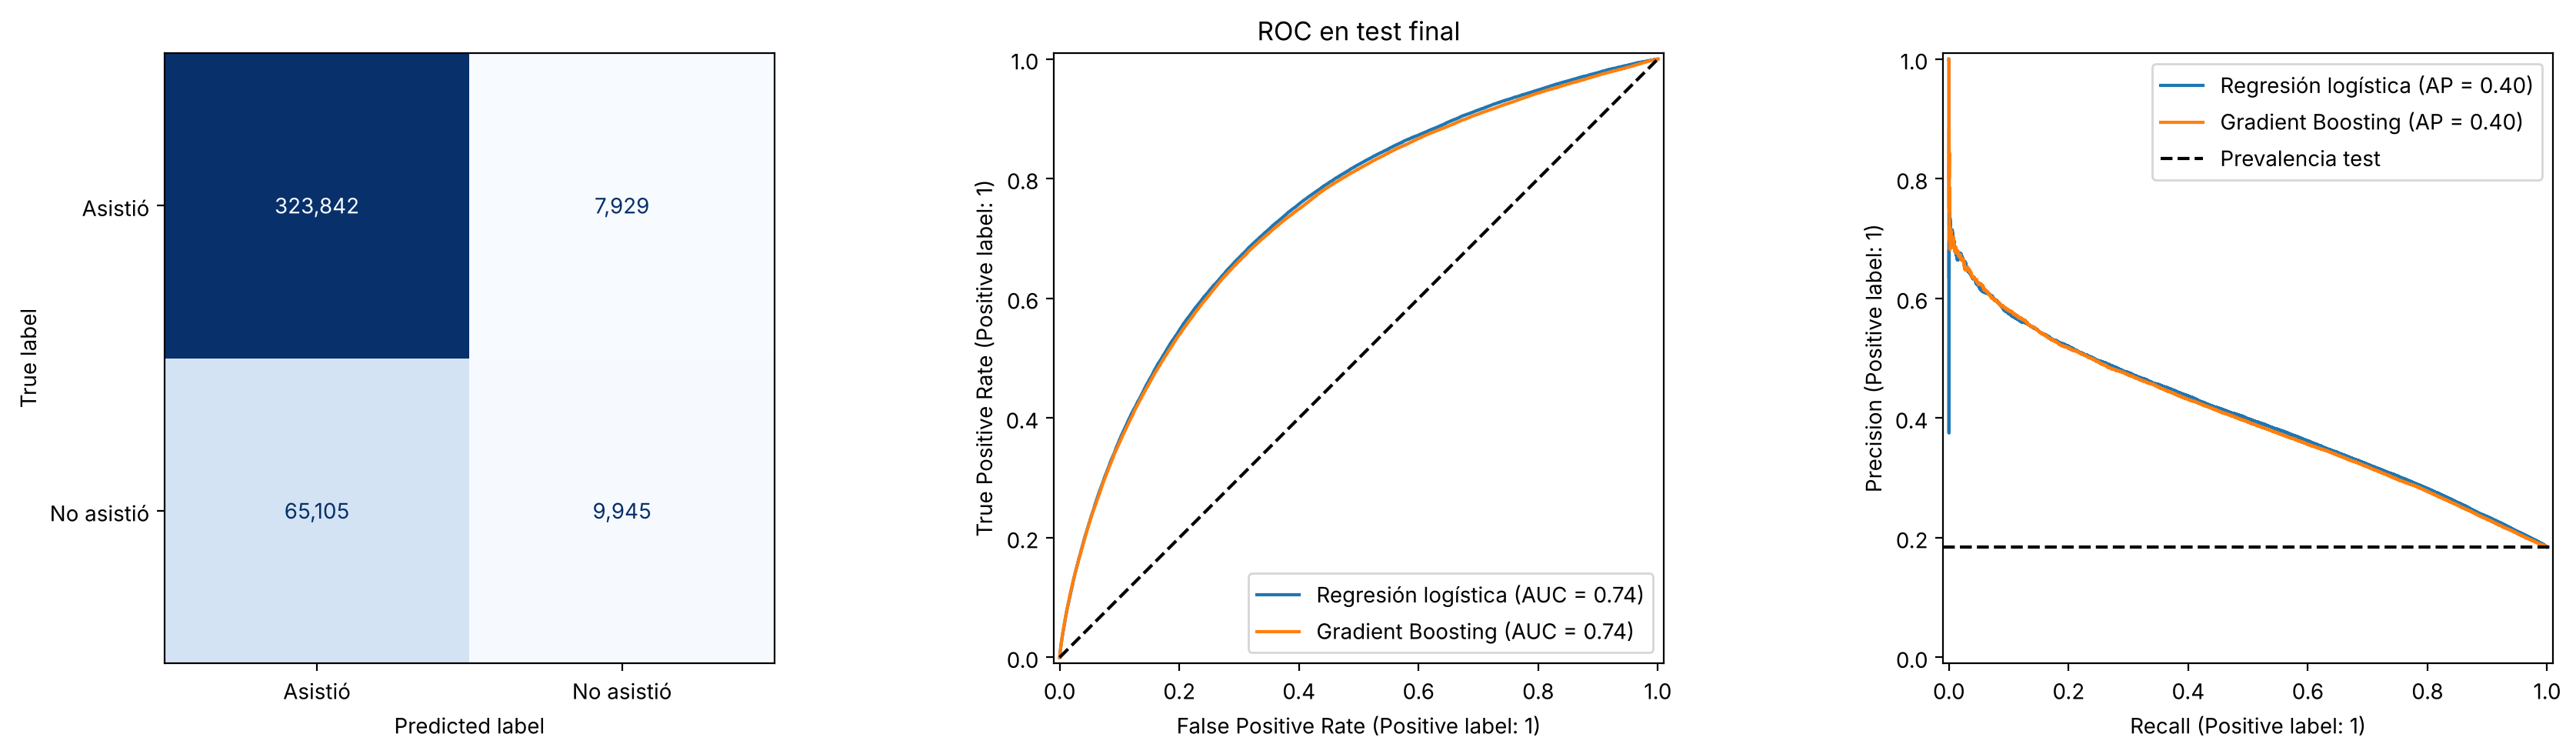

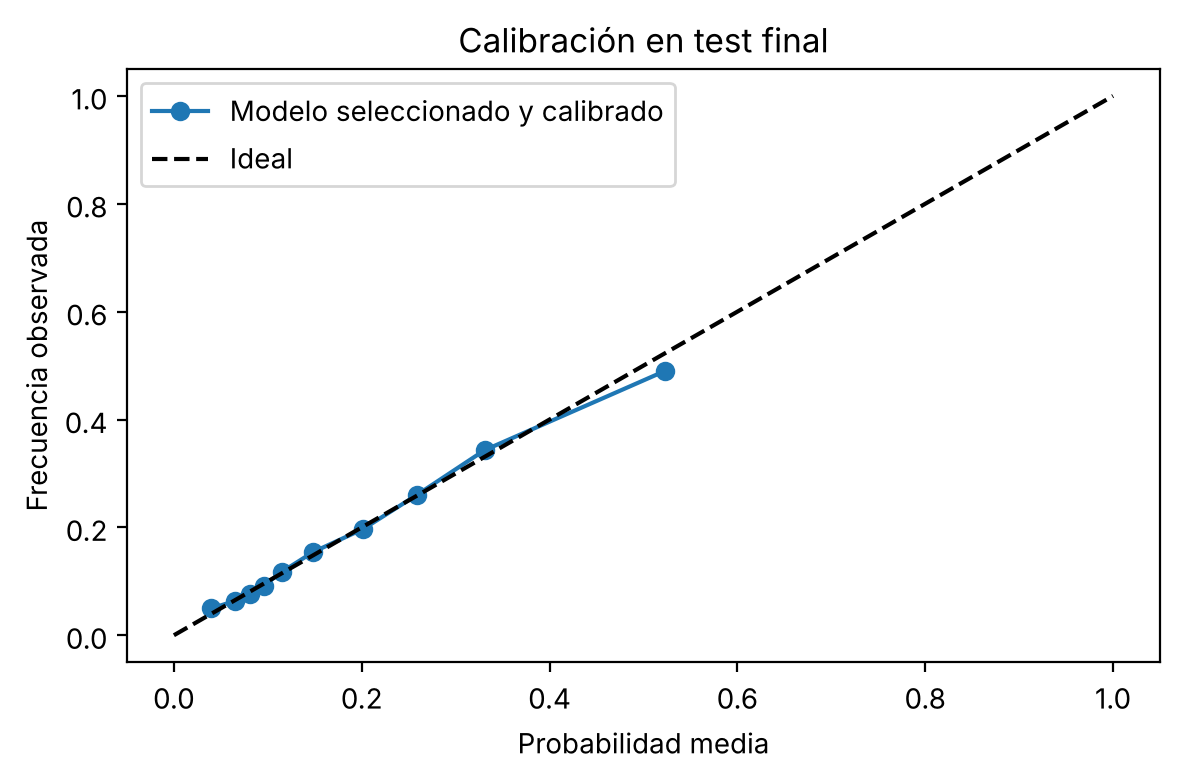

Probabilidad media: 18.59%; inasistencia real: 18.45%


In [15]:
# MEJOR ya quedó fijado en validación; aquí no se vuelve a seleccionar.
prob_test = probabilidades_test[MEJOR]
pred_test = prob_test >= 0.5
print('Modelo fijado antes del test:',MEJOR)
print(classification_report(y_test,pred_test,target_names=['Asistió','No asistió'],zero_division=0))
fig,ax = plt.subplots(1,3,figsize=(18,5))
ConfusionMatrixDisplay(confusion_matrix(y_test,pred_test),display_labels=['Asistió','No asistió']).plot(
    cmap='Blues',values_format=',',ax=ax[0],colorbar=False)
for nombre in ['Regresión logística','Gradient Boosting']:
    RocCurveDisplay.from_predictions(y_test,probabilidades_test[nombre],name=nombre,ax=ax[1])
    PrecisionRecallDisplay.from_predictions(y_test,probabilidades_test[nombre],name=nombre,ax=ax[2])
ax[1].plot([0,1],[0,1],'k--'); ax[1].set_title('ROC en test final')
ax[2].axhline(y_test.mean(),color='k',ls='--',label='Prevalencia test');ax[2].legend()
plt.tight_layout();plt.show()
fraccion,media = calibration_curve(y_test,prob_test,n_bins=10,strategy='quantile')
plt.figure(figsize=(6,4));plt.plot(media,fraccion,'o-',label='Modelo seleccionado y calibrado')
plt.plot([0,1],[0,1],'k--',label='Ideal');plt.xlabel('Probabilidad media');plt.ylabel('Frecuencia observada')
plt.title('Calibración en test final');plt.legend();plt.tight_layout();plt.show()
print(f'Probabilidad media: {prob_test.mean():.2%}; inasistencia real: {y_test.mean():.2%}')

### Importancia de variables y auditoría de equidad
La importancia por permutación describe el modelo globalmente; no sustituye una explicación individual (las explicaciones SHAP locales se generan en el Paso 7). La auditoría compara tasas de falsos positivos (FPR) y falsos negativos (FNR) entre grupos de edad, comuna y sede con el umbral alto fijado en validación, sin ajustarlo con test. Edad y comuna se usan aquí solo como grupos de auditoría.

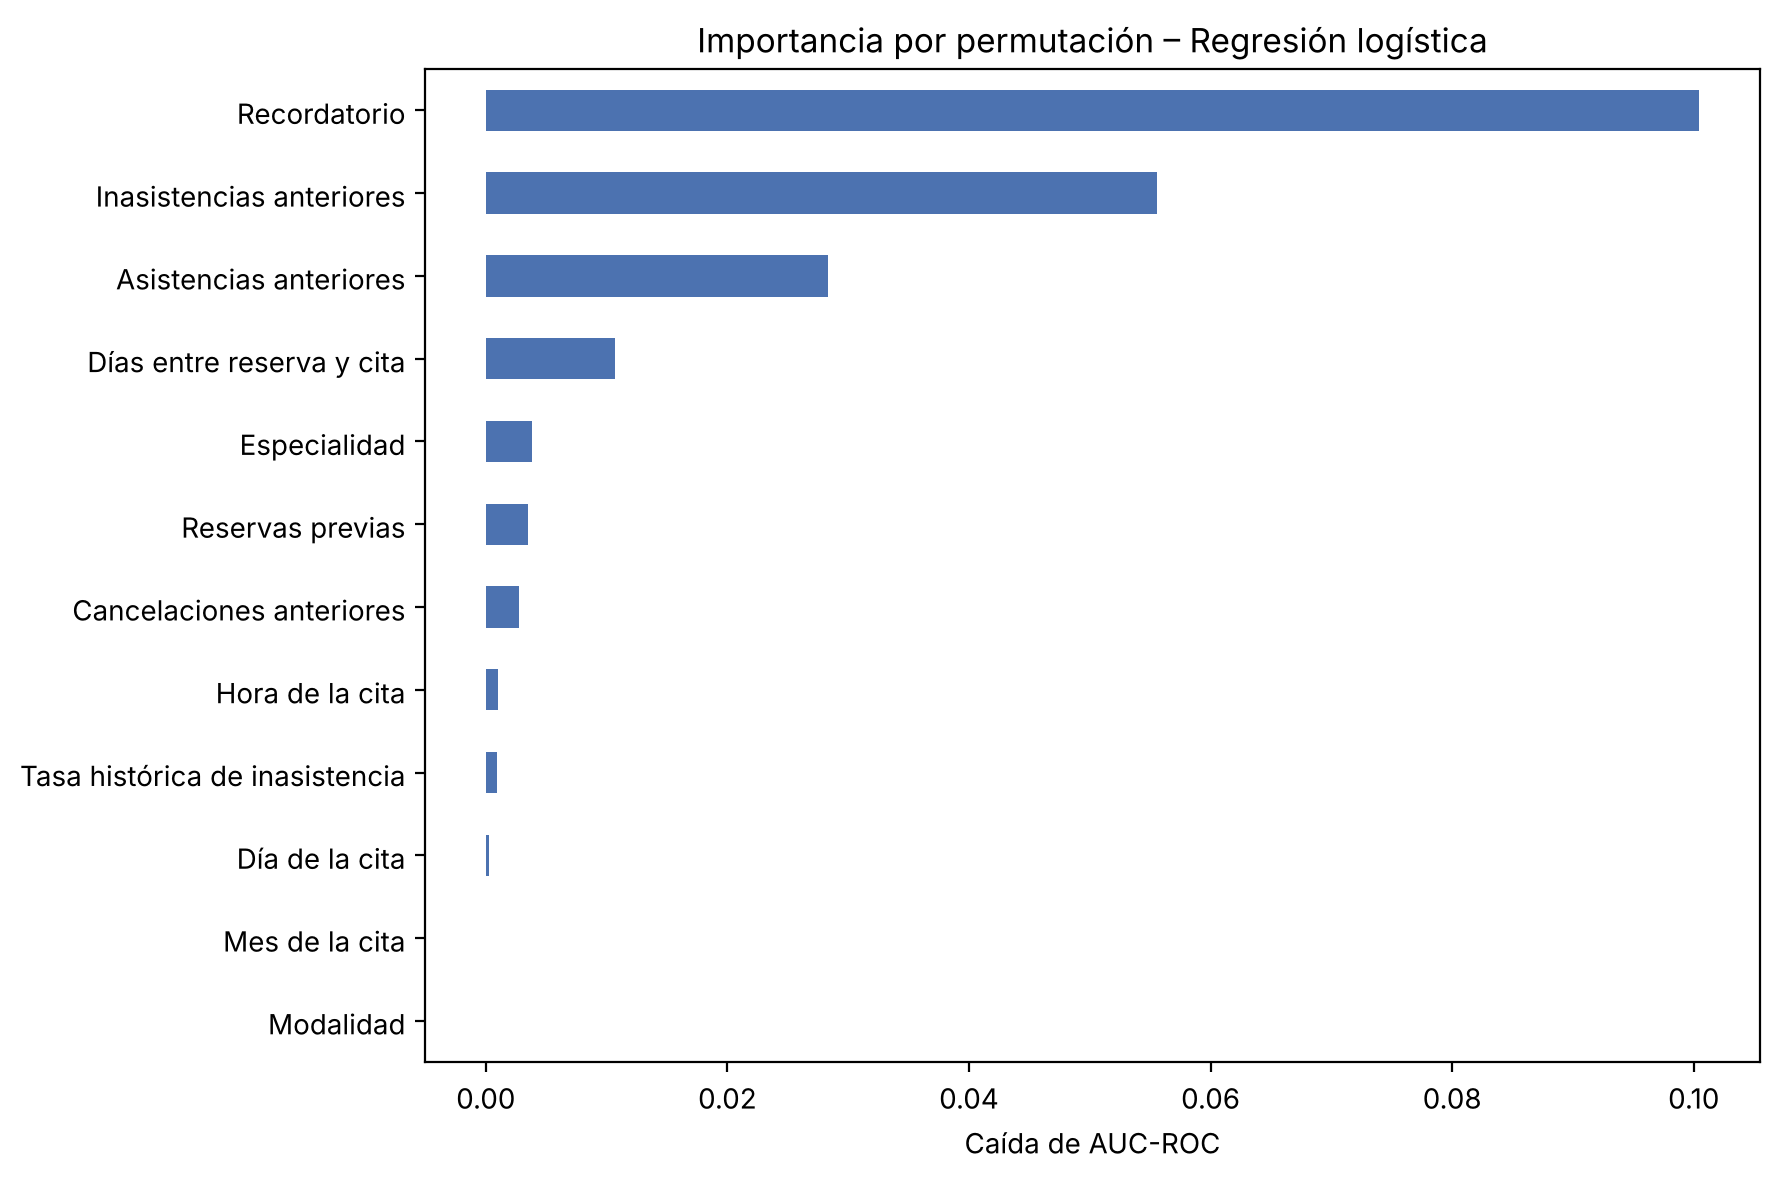

,brecha_FPR,brecha_FNR,rango_tasa_real,cumple_5pp
segmento,,,,
centro_medico,0.0299,0.0786,0.0601,False
comuna,0.0479,0.1484,0.0860,False
grupo_edad,0.0605,0.1506,0.1006,False


Detalle por grupo de edad:


,grupo,n,tasa_real,tasa_alerta,FPR,FNR
0,0-14,69505,0.175,0.091,0.059,0.757
1,15-29,72551,0.237,0.161,0.101,0.648
2,30-44,87865,0.195,0.126,0.082,0.691
3,45-64,102751,0.180,0.107,0.069,0.721
4,65+,74149,0.136,0.063,0.041,0.798


Auditoría ilustrativa, sin causalidad ni garantía de cumplimiento real. Brechas expresadas en proporciones.


In [16]:
from sklearn.inspection import permutation_importance

muestra = test.sample(min(15_000, len(test)), random_state=SEED)
imp = permutation_importance(modelo_final, muestra[VARIABLES], muestra[OBJETIVO],
    scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=1)
importancia = pd.Series(imp.importances_mean, index=VARIABLES).sort_values()
importancia.rename(index=sv.ETIQUETAS).plot.barh(figsize=(9, 6), color='#4C72B0',
                                                 title=f'Importancia por permutación – {MEJOR}')
plt.xlabel('Caída de AUC-ROC'); plt.tight_layout(); plt.show()

# Auditar con el umbral alto fijado en validación, sin ajustarlo con test.
auditoria = test[['edad', 'comuna', 'centro_medico', OBJETIVO]].copy()
auditoria['grupo_edad'] = pd.cut(auditoria.edad, [-1, 14, 29, 44, 64, 120], labels=['0-14', '15-29', '30-44', '45-64', '65+'])
auditoria['alerta'] = prob_test >= UMBRAL_ALTO
filas_equidad = []
for segmento in ['grupo_edad', 'comuna', 'centro_medico']:
    for grupo, d in auditoria.groupby(segmento, observed=True, dropna=False):
        positivos = d[OBJETIVO].eq(1); negativos = ~positivos
        filas_equidad.append({'segmento': segmento, 'grupo': str(grupo), 'n': len(d),
            'positivos': int(positivos.sum()), 'negativos': int(negativos.sum()),
            'tasa_real': positivos.mean(), 'tasa_alerta': d['alerta'].mean(),
            'FPR': d.loc[negativos, 'alerta'].mean(), 'FNR': (~d.loc[positivos, 'alerta']).mean()})
equidad = pd.DataFrame(filas_equidad)
# Umbral mínimo de muestra ilustrativo; debe acordarse con Operaciones/Privacidad.
equidad['muestra_suficiente'] = (equidad.positivos >= 100) & (equidad.negativos >= 100)
resumen_equidad = equidad[equidad.muestra_suficiente].groupby('segmento').agg(
    brecha_FPR=('FPR', lambda x: x.max() - x.min()), brecha_FNR=('FNR', lambda x: x.max() - x.min()),
    rango_tasa_real=('tasa_real', lambda x: x.max() - x.min()))
resumen_equidad['cumple_5pp'] = resumen_equidad[['brecha_FPR', 'brecha_FNR']].le(0.05).all(axis=1)
display(resumen_equidad.round(4))
print('Detalle por grupo de edad:')
display(equidad[equidad.segmento.eq('grupo_edad')][['grupo', 'n', 'tasa_real', 'tasa_alerta', 'FPR', 'FNR']].round(3))
print('Auditoría ilustrativa, sin causalidad ni garantía de cumplimiento real. Brechas expresadas en proporciones.')

### Lectura de la auditoría de equidad (RNF10)
**Resultado:** al excluir edad y sede, las brechas bajaron respecto de la versión anterior (brecha de FNR por edad de 0,23 a 0,15, por comuna de 0,23 a 0,15 y por sede de 0,20 a 0,08), pero **siguen sobre el límite de 0,05 del RNF10**. Por lo tanto, el RNF10 **no se cumple** y, según el plan, H03 no puede aprobarse sin una decisión documentada.

**Por qué ocurre:** las tasas reales de inasistencia son distintas entre grupos (en edad van de 13,6% en 65+ a 23,7% en 15–29). Con un único umbral, los grupos con más inasistencias reciben más alertas y tienen menos falsos negativos. Cuando las tasas base difieren, no es posible igualar a la vez la calibración y las tasas de error entre grupos; excluir variables sensibles reduce la brecha, pero no la elimina, porque el historial del paciente también refleja esas diferencias.

**Qué grupo queda más expuesto:** los mayores de 65 tienen el FNR más alto (0,80): sus inasistencias se detectan menos y reciben menos contactos. Esto refuerza la medida E3 del plan: el canal de llamada humana y el recordatorio habitual se mantienen para todos, independientemente del score.

**Acciones propuestas antes de H03:**
1. Revisar con Operaciones y Privacidad si el límite de 5 pp debe medirse sobre la política real (medio + alto con tope diario) y no solo sobre el umbral alto, que señala apenas el 11% de las reservas.
2. Evaluar umbrales diferenciados por grupo de edad. Mejoran la equidad de errores, pero implican usar la edad en la decisión, por lo que requieren aprobación ética y legal explícita.
3. Mantener la auditoría en el piloto con datos reales; en datos sintéticos las brechas dependen de los efectos simulados.

### 6.1 Mitigación de equidad (tarea T12, acción correctiva AC02)
La auditoría anterior no cumple el RNF10. Se evalúa una política alternativa **sin cambiar el modelo**: umbrales de contacto por grupo de edad, elegidos para que todos los grupos tengan la misma tasa de falsos negativos que la política "medio o alto" en la ventana de calibración.

- Los umbrales se fijan **solo con la ventana de calibración** (octubre–diciembre 2024) y se evalúan **una vez** en el test 2025.
- La edad no entra al modelo: solo define qué umbral de contacto se aplica. Aun así, usarla en la decisión requiere aprobación de Privacidad antes del piloto (H06).
- Se comparan tres políticas: umbral alto único, umbral medio único y umbrales por edad.

In [17]:
grupos_edad, etiquetas_edad = [-1, 14, 29, 44, 64, 120], ['0-14', '15-29', '30-44', '45-64', '65+']
g_cal = pd.cut(valid_calibracion['edad'], grupos_edad, labels=etiquetas_edad).astype(object).to_numpy()
g_test = pd.cut(test['edad'], grupos_edad, labels=etiquetas_edad).astype(object).to_numpy()
pos_cal, pos_test = y_cal.to_numpy() == 1, y_test.to_numpy() == 1

# Umbral por grupo: el cuantil de las probabilidades de los positivos que deja la misma tasa de
# falsos negativos que la política "medio o alto" en calibración. Nada de esto mira el test.
fnr_objetivo = (prob_cal[pos_cal] < UMBRAL_MEDIO).mean()
UMBRALES_EDAD = {g: float(np.quantile(prob_cal[pos_cal & (g_cal == g)], fnr_objetivo)) for g in etiquetas_edad}
umbral_por_reserva = np.array([UMBRALES_EDAD.get(g, UMBRAL_MEDIO) for g in g_test])
print(f'FNR objetivo fijado en calibración: {fnr_objetivo:.3f}')
print('Umbrales por grupo de edad:', {g: round(u, 3) for g, u in UMBRALES_EDAD.items()})

def brecha(alerta, segmento):
    fnr, fpr = [], []
    for g in pd.unique(segmento):
        m = segmento == g
        if (m & pos_test).sum() < 100 or (m & ~pos_test).sum() < 100:
            continue
        fnr.append((~alerta[m & pos_test]).mean()); fpr.append(alerta[m & ~pos_test].mean())
    return max(fnr) - min(fnr), max(fpr) - min(fpr)

comuna_test = test['comuna'].astype(object).fillna('Desconocida').to_numpy()
sede_test = test['centro_medico'].to_numpy()
filas = []
for nombre, alerta in [('Umbral alto único', prob_test >= UMBRAL_ALTO),
                       ('Umbral medio único', prob_test >= UMBRAL_MEDIO),
                       ('Umbrales por edad', prob_test >= umbral_por_reserva)]:
    fe, pe = brecha(alerta, g_test.astype(str))
    fc, pc = brecha(alerta, comuna_test)
    fs, ps = brecha(alerta, sede_test)
    filas.append({'política': nombre, '% señaladas': alerta.mean() * 100, 'recall': alerta[pos_test].mean(),
                  'precisión': pos_test[alerta].mean(), 'brecha FNR edad': fe, 'brecha FPR edad': pe,
                  'brecha FNR comuna': fc, 'brecha FNR sede': fs})
mitigacion = pd.DataFrame(filas).set_index('política')
display(mitigacion.round(3))
print('Límite RNF10: brechas de 0,05. Grupos con menos de 100 positivos o negativos se excluyen del cálculo.')

FNR objetivo fijado en calibración: 0.410
Umbrales por grupo de edad: {'0-14': 0.223, '15-29': 0.259, '30-44': 0.24, '45-64': 0.238, '65+': 0.194}


,% señaladas,recall,precisión,brecha FNR edad,brecha FPR edad,brecha FNR comuna,brecha FNR sede
política,,,,,,,
Umbral alto único,10.993,0.287,0.481,0.151,0.060,0.148,0.079
Umbral medio único,29.283,0.584,0.368,0.162,0.126,0.113,0.053
Umbrales por edad,29.708,0.585,0.363,0.025,0.023,0.123,0.054


Límite RNF10: brechas de 0,05. Grupos con menos de 100 positivos o negativos se excluyen del cálculo.


**Lectura y decisión del hito M03 (09/11).** Con umbrales por edad, la brecha de falsos negativos por edad baja de 0,16 a 0,03 y la de falsos positivos de 0,13 a 0,02, con el mismo recall (58%) y casi la misma precisión. La brecha por comuna no mejora (de 0,11 a 0,12) y la de sede queda apenas sobre el límite (0,054).

Decisión: el modelo se **acepta para el piloto con condiciones**, no para uso general:
1. Privacidad debe aprobar el uso de la edad en el umbral de contacto antes de H06; mientras tanto se mantiene el umbral único.
2. La brecha por comuna se monitorea en el piloto, que al ser de una sola sede acota ese riesgo.
3. El recordatorio habitual y la llamada humana se mantienen para todos, sin depender solo del score.

### Umbral de decisión según capacidad operativa
Los umbrales alto y medio ya se fijaron con validación/calibración (percentiles 90 y 70). Aquí solo se describe su desempeño en test, sin reajustarlos. Además se evalúa una política diaria con máximo de contactos en la sucursal piloto. Los porcentajes de captura indican inasistencias identificadas en datos históricos, no inasistencias evitadas por la intervención.

In [18]:
filas_captura=[]
for nivel,u in [('Alto',UMBRAL_ALTO),('Medio o alto',UMBRAL_MEDIO)]:
    alerta=prob_test>=u
    filas_captura.append({'política':nivel,'umbral fijado en validación':u,
        '% reservas señaladas':alerta.mean()*100,
        '% inasistencias identificadas':y_test.to_numpy()[alerta].sum()/y_test.sum()*100,
        'precisión del grupo':y_test.to_numpy()[alerta].mean() if alerta.any() else np.nan})
captura=pd.DataFrame(filas_captura)
display(captura.round(4))
politica=test[['id_reserva','centro_medico','fecha_atencion',OBJETIVO]].copy()
politica['p']=prob_test
piloto=politica[politica.centro_medico.eq(SUCURSAL_PILOTO)].copy()
contactos=(piloto[piloto.p>=UMBRAL_MEDIO].sort_values(['fecha_atencion','p','id_reserva'],ascending=[True,False,True])
           .groupby('fecha_atencion',group_keys=False).head(CAPACIDAD_DIARIA))
print('Política piloto:',SUCURSAL_PILOTO,'| máximo contactos/día:',CAPACIDAD_DIARIA)
print('Reservas piloto:',len(piloto),'| contactos seleccionados:',len(contactos))
print('Recall operativo:',contactos[OBJETIVO].sum()/piloto[OBJETIVO].sum())
print('Precisión operativa:',contactos[OBJETIVO].mean())
assert contactos.groupby('fecha_atencion').size().le(CAPACIDAD_DIARIA).all()

,política,umbral fijado en validación,% reservas señaladas,% inasistencias identificadas,precisión del grupo
0,Alto,0.3716,10.9928,28.6676,0.4811
1,Medio o alto,0.2349,29.2834,58.4397,0.3682


Política piloto: Providencia | máximo contactos/día: 30
Reservas piloto: 21635 | contactos seleccionados: 5960
Recall operativo: 0.5687309080810886
Precisión operativa: 0.3436241610738255


## Paso 7. Usar el modelo con nuevos datos para generar 5 predicciones
Se crean cinco reservas ficticias no utilizadas para entrenar ni validar. Cada una representa una ejecución a las 20:00 del día anterior a su cita, con antecedentes y confirmación conocidos al corte. Se aplican las mismas funciones del módulo compartido y el mismo paquete que usará la automatización. Se presentan probabilidades calibradas, nivel de riesgo, acción sugerida y los **tres factores principales en lenguaje legible** para el personal, sin afirmar certeza sobre la asistencia.

In [19]:
nuevas = pd.DataFrame([
    # joven, mucha anticipación, historial con inasistencias, sin confirmar
    dict(edad=24, comuna='La Pintana', centro_medico='Puente Alto', especialidad='Dermatología',
         fecha_solicitud='2026-10-01', fecha_atencion='2026-11-02', horario_atencion='08:00',
         asistencias_anteriores=1, cancelaciones_anteriores=1, inasistencias_anteriores=3,
         tipo_prevision='FONASA A', modalidad_atencion='Presencial', confirmacion_recordatorio='No respondió'),
    # adulto mayor, cardiología, buen historial, confirmó
    dict(edad=71, comuna='Las Condes', centro_medico='Las Condes', especialidad='Cardiología',
         fecha_solicitud='2026-10-12', fecha_atencion='2026-11-03', horario_atencion='10:20',
         asistencias_anteriores=8, cancelaciones_anteriores=0, inasistencias_anteriores=0,
         tipo_prevision='ISAPRE', modalidad_atencion='Presencial', confirmacion_recordatorio='Confirmó'),
    # niño, pediatría, hora para el día siguiente, confirmó
    dict(edad=6, comuna='Maipú', centro_medico='Maipú', especialidad='Pediatría',
         fecha_solicitud='2026-11-03', fecha_atencion='2026-11-04', horario_atencion='16:00',
         asistencias_anteriores=4, cancelaciones_anteriores=0, inasistencias_anteriores=1,
         tipo_prevision='FONASA C', modalidad_atencion='Presencial', confirmacion_recordatorio='Confirmó'),
    # adulto, medicina general por telemedicina, primera reserva, sin confirmar
    dict(edad=38, comuna='Santiago', centro_medico='Santiago Centro', especialidad='Medicina general',
         fecha_solicitud='2026-10-28', fecha_atencion='2026-11-02', horario_atencion='12:40',
         asistencias_anteriores=0, cancelaciones_anteriores=0, inasistencias_anteriores=0,
         tipo_prevision='FONASA B', modalidad_atencion='Telemedicina', confirmacion_recordatorio='No respondió'),
    # centro migrado: edad, comuna y previsión faltantes (solo la edad era candidata a predictor;
    # comuna y previsión no entran al modelo)
    dict(edad=np.nan, comuna=np.nan, centro_medico='San Bernardo', especialidad='Traumatología',
         fecha_solicitud='2026-10-05', fecha_atencion='2026-11-05', horario_atencion='18:20',
         asistencias_anteriores=2, cancelaciones_anteriores=0, inasistencias_anteriores=2,
         tipo_prevision=np.nan, modalidad_atencion='Presencial', confirmacion_recordatorio='No respondió'),
])

nuevas['id_reserva'] = [f'NUEVA-{i}' for i in range(1, 6)]
nuevas['id_paciente'] = [f'FICTICIO-{i}' for i in range(1, 6)]
nuevas['fecha_solicitud'] = pd.to_datetime(nuevas.fecha_solicitud)
nuevas['fecha_atencion'] = pd.to_datetime(nuevas.fecha_atencion)
nuevas['fecha_hora_atencion'] = nuevas.fecha_atencion + pd.to_timedelta(nuevas.horario_atencion + ':00')
nuevas['fecha_hora_solicitud'] = nuevas.fecha_solicitud + pd.Timedelta(hours=7)
nuevas['fecha_prediccion'] = nuevas.fecha_atencion - pd.Timedelta(days=1) + pd.Timedelta(hours=20)
nuevas['fecha_cancelacion'] = pd.NaT
nuevas['fecha_confirmacion'] = (nuevas.fecha_hora_atencion - pd.Timedelta(hours=23, minutes=30)).where(
    nuevas.confirmacion_recordatorio.eq('Confirmó'))
nuevas['dias_anticipacion'] = (nuevas.fecha_atencion - nuevas.fecha_solicitud).dt.days
nuevas['confirmacion_recordatorio'] = np.where(nuevas.fecha_confirmacion.notna() &
    nuevas.fecha_confirmacion.le(nuevas.fecha_prediccion), 'Confirmó', 'Sin confirmación al corte')
assert nuevas.fecha_hora_solicitud.le(nuevas.fecha_prediccion).all()

nuevas_x = sv.crear_variables(nuevas)
nuevas['prob_inasistencia'] = sv.probabilidad(paquete, nuevas_x[VARIABLES])
nuevas['nivel_riesgo'] = sv.nivel_riesgo(paquete, nuevas.prob_inasistencia)
nuevas['accion_sugerida'] = nuevas.nivel_riesgo.map(ACCIONES)
nuevas['factores_principales'], contribuciones, base_shap = sv.explicar(paquete, nuevas_x)
print('Probabilidad calibrada: estimación, no certeza. Factores: contribuciones SHAP al score bruto, agrupadas por variable.')
with pd.option_context('display.max_colwidth', None):
    display(nuevas[['id_reserva', 'especialidad', 'dias_anticipacion', 'inasistencias_anteriores',
                    'confirmacion_recordatorio', 'prob_inasistencia', 'nivel_riesgo', 'accion_sugerida',
                    'factores_principales']].round({'prob_inasistencia': 3}))
print(f'Valor base SHAP (log-odds): {base_shap:.4f}')
display(contribuciones.set_axis(nuevas.id_reserva).round(3))

Probabilidad calibrada: estimación, no certeza. Factores: contribuciones SHAP al score bruto, agrupadas por variable.


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,id_reserva,especialidad,dias_anticipacion,inasistencias_anteriores,confirmacion_recordatorio,prob_inasistencia,nivel_riesgo,accion_sugerida,factores_principales
0,NUEVA-1,Dermatología,32,3,Sin confirmación al corte,0.610,Alto,"Priorizar llamada humana y solicitar confirmación, sin alterar la reserva",Recordatorio: Sin confirmación al corte (↑ riesgo); Inasistencias anteriores: 3 (↑ riesgo); Tasa histórica de inasistencia: 75% (↑ riesgo)
1,NUEVA-2,Cardiología,22,0,Confirmó,0.062,Bajo,Mantener recordatorio habitual; sin contacto adicional por el score,Recordatorio: Confirmó (↓ riesgo); Especialidad: Cardiología (↓ riesgo); Asistencias anteriores: 8 (↓ riesgo)
2,NUEVA-3,Pediatría,1,1,Confirmó,0.086,Bajo,Mantener recordatorio habitual; sin contacto adicional por el score,Recordatorio: Confirmó (↓ riesgo); Días entre reserva y cita: 1 (↓ riesgo); Inasistencias anteriores: 1 (↑ riesgo)
3,NUEVA-4,Medicina general,5,0,Sin confirmación al corte,0.317,Medio,Contacto preventivo por canal institucional autorizado antes de la cita,Recordatorio: Sin confirmación al corte (↑ riesgo); Asistencias anteriores: 0 (↑ riesgo); Inasistencias anteriores: 0 (↓ riesgo)
4,NUEVA-5,Traumatología,31,2,Sin confirmación al corte,0.415,Alto,"Priorizar llamada humana y solicitar confirmación, sin alterar la reserva",Recordatorio: Sin confirmación al corte (↑ riesgo); Inasistencias anteriores: 2 (↑ riesgo); Días entre reserva y cita: 31 (↑ riesgo)


Valor base SHAP (log-odds): -0.2068


,dias_anticipacion,asistencias_anteriores,inasistencias_anteriores,cancelaciones_anteriores,reservas_previas,tasa_inasistencia_hist,hora_atencion,dia_semana,mes,especialidad,modalidad_atencion,confirmacion_recordatorio
id_reserva,,,,,,,,,,,,
NUEVA-1,0.281,0.149,0.505,0.060,-0.004,0.289,0.082,0.040,-0.012,0.141,-0.003,0.811
NUEVA-2,0.127,-0.242,-0.140,-0.042,-0.051,-0.043,0.050,0.021,-0.012,-0.326,-0.003,-0.544
NUEVA-3,-0.198,-0.018,0.075,-0.042,-0.004,0.046,-0.044,0.002,-0.012,-0.058,-0.003,-0.544
NUEVA-4,-0.136,0.205,-0.140,-0.042,0.074,-0.043,0.019,0.040,-0.012,0.112,0.096,0.811
NUEVA-5,0.266,0.093,0.290,-0.042,0.011,0.178,-0.076,-0.017,-0.012,-0.044,-0.003,0.811


**Lectura.** Las explicaciones ahora se pueden leer sin conocimientos técnicos. Por ejemplo, NUEVA-1 queda en riesgo alto porque no ha confirmado el recordatorio y acumula 3 inasistencias (75% de su historial); NUEVA-2 queda en riesgo bajo porque confirmó, es de cardiología y tiene 8 asistencias previas. Las contribuciones agrupadas por variable (tabla inferior) suman el score bruto del modelo junto con el valor base, lo que permite verificar cada explicación (trazabilidad del caso).

NUEVA-5 proviene de un centro migrado con edad, comuna y previsión faltantes. Como ninguna de esas variables entra al modelo final, su predicción no depende de una imputación.

## Paso 8. Proponer e implementar una automatización

**Propuesta:** proceso diario a las 20:00 que prioriza contactos preventivos para las citas del día siguiente en la sucursal piloto.
1. Recibe reservas con marcas de creación, cancelación y confirmación; **no necesita el resultado final**.
2. Selecciona solo reservas existentes y vigentes al corte. Usa exclusivamente confirmaciones e historial conocidos entonces.
3. Aplica el modelo y la calibración guardados; asigna riesgos con umbrales definidos en validación.
4. Selecciona como máximo la capacidad diaria de contacto entre reservas de riesgo medio/alto, explica cada una en lenguaje legible y exporta una lista mínima para personal autorizado.
5. Registra ejecución, versión, fecha simulada y cantidad de contactos. Un día sin reservas genera una salida vacía válida. Una repetición reemplaza la misma salida sin duplicar contactos; no envía mensajes ni modifica reservas.

**Autonomía (corrección v2.1):** todo lo que el proceso necesita queda en dos archivos: el paquete `.joblib` (pipeline, calibrador, fondo SHAP, variables, umbrales y acciones) y el `config.json` (sucursal, capacidad, hora). El script `automatizacion.py` solo importa el módulo compartido, por lo que puede programarse (por ejemplo, con Azure Functions o una tarea programada) sin abrir este notebook. Se prueba ejecutándolo en un **proceso Python independiente**.

Las acciones se realizan antes de la cita, sin prometer recordatorios a 48 h cuando esa ventana ya pasó. No responder no libera el cupo. La lista de espera solo puede ocupar cupos efectivamente liberados mediante el procedimiento institucional.

Aquí se implementa y prueba el procesamiento local. La consulta SQL, la programación horaria, los accesos por rol y el cifrado son integración pendiente para producción; no se afirma haberlos desplegado. Las salidas contienen identificadores artificiales y deben ser accesibles únicamente a personal autorizado en una implementación real. El log no registra nombres ni datos de contacto.

In [20]:
import joblib, json, os, sklearn

os.makedirs('modelo', exist_ok=True)
VERSION = 'v2.1'
paquete['version'] = VERSION
joblib.dump(paquete, f'modelo/modelo_inasistencia_{VERSION}.joblib')
config = {'version': VERSION, 'algoritmo': MEJOR, 'criterio_seleccion': motivo, 'sklearn': sklearn.__version__,
    'entrenamiento_hasta': str(train.fecha_prediccion.max()),
    'seleccion_hasta': str(valid_modelo.fecha_prediccion.max()),
    'calibracion_hasta': str(valid_calibracion.fecha_prediccion.max()),
    'variables_numericas': VAR_NUMERICAS, 'variables_categoricas': VAR_CATEGORICAS,
    'variables_excluidas_por_prueba': VARIABLES_EXCLUIDAS,
    'umbral_alto': UMBRAL_ALTO, 'umbral_medio': UMBRAL_MEDIO,
    'sucursal_piloto': SUCURSAL_PILOTO, 'capacidad_diaria': CAPACIDAD_DIARIA, 'hora_proceso': 20,
    'auc_test': float(metricas.loc[MEJOR, 'AUC-ROC']),
    'demostracion_academica': True, 'rnf10_cumplido': bool(resumen_equidad.cumple_5pp.all())}
with open(f'modelo/config_{VERSION}.json', 'w', encoding='utf-8') as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print(json.dumps(config, indent=2, ensure_ascii=False))

{
  "version": "v2.1",
  "algoritmo": "Regresión logística",
  "criterio_seleccion": "empate técnico (diferencia 0.0006 < 0,005): se prefiere el modelo más simple e interpretable",
  "sklearn": "1.9.1",
  "entrenamiento_hasta": "2024-06-28 20:00:00",
  "seleccion_hasta": "2024-09-27 20:00:00",
  "calibracion_hasta": "2024-12-29 20:00:00",
  "variables_numericas": [
    "dias_anticipacion",
    "asistencias_anteriores",
    "inasistencias_anteriores",
    "cancelaciones_anteriores",
    "reservas_previas",
    "tasa_inasistencia_hist",
    "hora_atencion",
    "dia_semana",
    "mes"
  ],
  "variables_categoricas": [
    "especialidad",
    "modalidad_atencion",
    "confirmacion_recordatorio"
  ],
  "variables_excluidas_por_prueba": [
    "edad",
    "centro_medico"
  ],
  "umbral_alto": 0.371616511428038,
  "umbral_medio": 0.23493740255186896,
  "sucursal_piloto": "Providencia",
  "capacidad_diaria": 30,
  "hora_proceso": 20,
  "auc_test": 0.7423447845421243,
  "demostracion_academica

In [21]:
%%writefile automatizacion.py
"""Proceso diario SaludConex (20:00): lista priorizada de contactos preventivos para la sucursal piloto.

No contacta, no cancela y no modifica reservas. Solo necesita el paquete del modelo, su configuración
y el módulo compartido saludconex_variables.py.

Uso:
    python automatizacion.py --datos saludconex_reservas_2023_2025.csv --corte "2025-11-30 20:00"
"""
import argparse
import json
import os
from datetime import datetime

import joblib
import pandas as pd

from saludconex_variables import preparar_reservas, probabilidad, nivel_riesgo, explicar, variables_modelo

FECHAS = ['fecha_solicitud', 'fecha_atencion', 'fecha_hora_atencion', 'fecha_hora_solicitud',
          'fecha_prediccion', 'fecha_cancelacion', 'fecha_confirmacion']
COLUMNAS_SALIDA = ['id_reserva', 'id_paciente', 'centro_medico', 'fecha_atencion', 'horario_atencion',
                   'prob_inasistencia', 'nivel_riesgo', 'accion_sugerida', 'factores_principales', 'version_modelo']


def cargar_modelo(version, carpeta_modelo='modelo'):
    with open(f'{carpeta_modelo}/config_{version}.json', encoding='utf-8') as f:
        cfg = json.load(f)
    paquete = joblib.load(f'{carpeta_modelo}/modelo_inasistencia_{version}.joblib')
    return cfg, paquete


def generar_lista_acciones(reservas, fecha_proceso, version='v2.1', carpeta='salidas', carpeta_modelo='modelo'):
    """Genera la lista diaria. No accede al resultado final, no contacta ni cancela."""
    cfg, paquete = cargar_modelo(version, carpeta_modelo)
    corte = pd.Timestamp(fecha_proceso)
    if corte.hour != cfg['hora_proceso'] or corte.minute or corte.second:
        raise ValueError(f"El proceso diario requiere corte a las {cfg['hora_proceso']}:00")
    fecha_obj = corte.normalize() + pd.Timedelta(days=1)

    dia = reservas[pd.to_datetime(reservas.fecha_atencion).eq(fecha_obj) &
                   reservas.centro_medico.eq(cfg['sucursal_piloto'])].copy()
    # Eliminar la etiqueta si viniera en datos retrospectivos; nunca se consulta para decidir.
    dia = preparar_reservas(dia.drop(columns=['resultado_reserva'], errors='ignore'), corte)
    evaluables = len(dia)
    if not dia.empty:
        dia['prob_inasistencia'] = probabilidad(paquete, dia[variables_modelo(paquete)])
        dia['nivel_riesgo'] = nivel_riesgo(paquete, dia['prob_inasistencia'])
        dia = (dia[dia.nivel_riesgo.isin(['Alto', 'Medio'])]
               .sort_values(['prob_inasistencia', 'id_reserva'], ascending=[False, True])
               .head(cfg['capacidad_diaria']).copy())
    if dia.empty:
        salida = pd.DataFrame(columns=COLUMNAS_SALIDA)
    else:
        dia['accion_sugerida'] = dia['nivel_riesgo'].map(paquete['acciones'])
        dia['factores_principales'], _, _ = explicar(paquete, dia)
        dia['version_modelo'] = version
        salida = dia[COLUMNAS_SALIDA].reset_index(drop=True)

    os.makedirs(carpeta, exist_ok=True)
    archivo = f"{carpeta}/acciones_preventivas_{cfg['sucursal_piloto']}_{fecha_obj.date()}.csv"
    salida.to_csv(archivo, index=False)
    conteo = salida['nivel_riesgo'].value_counts().to_dict()
    log = {'ejecucion_real': datetime.now().isoformat(timespec='seconds'), 'corte_simulado': str(corte),
           'fecha_atencion': str(fecha_obj.date()), 'version_modelo': version, 'sucursal': cfg['sucursal_piloto'],
           'capacidad_diaria': cfg['capacidad_diaria'], 'reservas_evaluables': evaluables,
           'contactos': len(salida), 'alto': int(conteo.get('Alto', 0)), 'medio': int(conteo.get('Medio', 0)),
           'archivo': archivo}
    ruta_log = f'{carpeta}/log_ejecuciones.csv'
    logs = pd.read_csv(ruta_log) if os.path.exists(ruta_log) else pd.DataFrame()
    logs = pd.concat([logs, pd.DataFrame([log])], ignore_index=True)
    logs = logs.drop_duplicates(['corte_simulado', 'version_modelo', 'sucursal'], keep='last')
    logs.to_csv(ruta_log, index=False)
    return salida, log


def main():
    parser = argparse.ArgumentParser(description='Lista diaria de contactos preventivos SaludConex')
    parser.add_argument('--datos', required=True, help='CSV de reservas con historial calculado al corte')
    parser.add_argument('--corte', required=True, help='Fecha y hora del corte, p. ej. "2025-11-30 20:00"')
    parser.add_argument('--version', default='v2.1')
    parser.add_argument('--salida', default='salidas')
    args = parser.parse_args()
    reservas = pd.read_csv(args.datos, parse_dates=FECHAS)
    salida, log = generar_lista_acciones(reservas, args.corte, args.version, args.salida)
    print(json.dumps(log, ensure_ascii=False))
    print(salida[['id_reserva', 'horario_atencion', 'prob_inasistencia', 'nivel_riesgo']].head(5).to_string(index=False))


if __name__ == '__main__':
    main()

Overwriting automatizacion.py


### Prueba 1: ejecución en un proceso Python independiente
Se ejecuta el script desde la línea de comandos, en un proceso nuevo que **no comparte memoria con este notebook**. Si funciona, la automatización es autónoma.

In [22]:
import subprocess, sys
resultado = subprocess.run([sys.executable, 'automatizacion.py', '--datos', RUTA,
                            '--corte', '2025-11-30 20:00', '--salida', 'salidas_cli'],
                           capture_output=True, text=True)
print(resultado.stdout)
if resultado.returncode != 0:
    print(resultado.stderr)
assert resultado.returncode == 0, 'El script autónomo falló'

{"ejecucion_real": "2026-11-08T18:37:42", "corte_simulado": "2025-11-30 20:00:00", "fecha_atencion": "2025-12-01", "version_modelo": "v2.1", "sucursal": "Providencia", "capacidad_diaria": 30, "reservas_evaluables": 78, "contactos": 18, "alto": 5, "medio": 13, "archivo": "salidas_cli/acciones_preventivas_Providencia_2025-12-01.csv"}
 id_reserva horario_atencion  prob_inasistencia nivel_riesgo
RES-1499945            17:40           0.490274         Alto
RES-1505819            18:20           0.482319         Alto
RES-1478656            18:00           0.430918         Alto
RES-1501302            10:20           0.421676         Alto
RES-1499993            08:00           0.372251         Alto



### Prueba 2: comprobaciones de la automatización
Se importa el mismo script desde el notebook y se verifica: entrada sin etiqueta, corte temporal, sede piloto, cupo diario, día vacío, repetición sin duplicados y **mismo resultado que la ejecución independiente**. Solo después se consultan las etiquetas reales para una validación retrospectiva.

In [23]:
import automatizacion
importlib.reload(automatizacion)

entrada_operativa = datos.drop(columns='resultado_reserva')
lista, log = automatizacion.generar_lista_acciones(entrada_operativa, '2025-11-30 20:00', VERSION)
print(log)
with pd.option_context('display.max_colwidth', None):
    display(lista.head(10))

# Validación retrospectiva: solo ahora se consultan las etiquetas reales de la simulación.
real = datos.drop_duplicates('id_reserva').set_index('id_reserva')['resultado_reserva']
chk = lista.assign(no_asistio=lista.id_reserva.map(real).eq('No asistió'))
resumen_dia = chk.groupby('nivel_riesgo').agg(contactos=('id_reserva', 'size'), inasistencias_reales=('no_asistio', 'sum'))
resumen_dia['% inasistencia real'] = resumen_dia.inasistencias_reales / resumen_dia.contactos * 100
display(resumen_dia)
print('Identificar casos no demuestra que una llamada haya evitado la inasistencia.')

# Comprobaciones
assert 'resultado_reserva' not in entrada_operativa
assert len(lista) <= CAPACIDAD_DIARIA
assert lista.centro_medico.eq(SUCURSAL_PILOTO).all()
creacion = datos.drop_duplicates('id_reserva').set_index('id_reserva').fecha_hora_solicitud
assert lista.id_reserva.map(creacion).le(pd.Timestamp('2025-11-30 20:00')).all()
vacia, _ = automatizacion.generar_lista_acciones(entrada_operativa, '2025-12-31 20:00', VERSION, carpeta='salidas_pruebas')
assert vacia.empty
repetida, _ = automatizacion.generar_lista_acciones(entrada_operativa, '2025-11-30 20:00', VERSION)
pd.testing.assert_frame_equal(lista, repetida)
assert lista.id_reserva.is_unique
cli = pd.read_csv(f"salidas_cli/acciones_preventivas_{SUCURSAL_PILOTO}_2025-12-01.csv")
assert cli.id_reserva.tolist() == lista.id_reserva.tolist(), 'El proceso independiente debe dar el mismo resultado'
print('Verificado: entrada sin etiqueta, corte temporal, sede piloto, cupo diario, día vacío, '
      'repetición sin duplicados y mismo resultado en un proceso independiente.')

{'ejecucion_real': '2026-11-08T18:37:43', 'corte_simulado': '2025-11-30 20:00:00', 'fecha_atencion': '2025-12-01', 'version_modelo': 'v2.1', 'sucursal': 'Providencia', 'capacidad_diaria': 30, 'reservas_evaluables': 78, 'contactos': 18, 'alto': 5, 'medio': 13, 'archivo': 'salidas/acciones_preventivas_Providencia_2025-12-01.csv'}


,id_reserva,id_paciente,centro_medico,fecha_atencion,horario_atencion,prob_inasistencia,nivel_riesgo,accion_sugerida,factores_principales,version_modelo
0,RES-1499945,PAC-137131,Providencia,2025-12-01,17:40,0.490274,Alto,"Priorizar llamada humana y solicitar confirmación, sin alterar la reserva",Inasistencias anteriores: 13 (↑ riesgo); Recordatorio: Confirmó (↓ riesgo); Asistencias anteriores: 11 (↓ riesgo),v2.1
1,RES-1505819,PAC-049978,Providencia,2025-12-01,18:20,0.482319,Alto,"Priorizar llamada humana y solicitar confirmación, sin alterar la reserva",Inasistencias anteriores: 6 (↑ riesgo); Recordatorio: Sin confirmación al corte (↑ riesgo); Asistencias anteriores: 10 (↓ riesgo),v2.1
2,RES-1478656,PAC-038287,Providencia,2025-12-01,18:00,0.430918,Alto,"Priorizar llamada humana y solicitar confirmación, sin alterar la reserva",Recordatorio: Sin confirmación al corte (↑ riesgo); Inasistencias anteriores: 3 (↑ riesgo); Días entre reserva y cita: 25 (↑ riesgo),v2.1
3,RES-1501302,PAC-120674,Providencia,2025-12-01,10:20,0.421676,Alto,"Priorizar llamada humana y solicitar confirmación, sin alterar la reserva",Inasistencias anteriores: 5 (↑ riesgo); Recordatorio: Sin confirmación al corte (↑ riesgo); Asistencias anteriores: 14 (↓ riesgo),v2.1
4,RES-1499993,PAC-156851,Providencia,2025-12-01,08:00,0.372251,Alto,"Priorizar llamada humana y solicitar confirmación, sin alterar la reserva",Inasistencias anteriores: 5 (↑ riesgo); Recordatorio: Sin confirmación al corte (↑ riesgo); Asistencias anteriores: 14 (↓ riesgo),v2.1
5,RES-1507821,PAC-142671,Providencia,2025-12-01,08:20,0.350601,Medio,Contacto preventivo por canal institucional autorizado antes de la cita,Recordatorio: Sin confirmación al corte (↑ riesgo); Inasistencias anteriores: 2 (↑ riesgo); Días entre reserva y cita: 1 (↓ riesgo),v2.1
6,RES-1497738,PAC-170175,Providencia,2025-12-01,18:00,0.347309,Medio,Contacto preventivo por canal institucional autorizado antes de la cita,Recordatorio: Sin confirmación al corte (↑ riesgo); Inasistencias anteriores: 4 (↑ riesgo); Asistencias anteriores: 9 (↓ riesgo),v2.1
7,RES-1479890,PAC-129473,Providencia,2025-12-01,13:00,0.321406,Medio,Contacto preventivo por canal institucional autorizado antes de la cita,Recordatorio: Sin confirmación al corte (↑ riesgo); Inasistencias anteriores: 4 (↑ riesgo); Asistencias anteriores: 15 (↓ riesgo),v2.1
8,RES-1455817,PAC-122069,Providencia,2025-12-01,17:20,0.318936,Medio,Contacto preventivo por canal institucional autorizado antes de la cita,Inasistencias anteriores: 5 (↑ riesgo); Recordatorio: Confirmó (↓ riesgo); Días entre reserva y cita: 42 (↑ riesgo),v2.1
9,RES-1487720,PAC-198419,Providencia,2025-12-01,11:20,0.316296,Medio,Contacto preventivo por canal institucional autorizado antes de la cita,Recordatorio: Sin confirmación al corte (↑ riesgo); Inasistencias anteriores: 3 (↑ riesgo); Especialidad: Cardiología (↓ riesgo),v2.1


,contactos,inasistencias_reales,% inasistencia real
nivel_riesgo,,,
Alto,5,3,60.000000
Medio,13,5,38.461538


Identificar casos no demuestra que una llamada haya evitado la inasistencia.


Verificado: entrada sin etiqueta, corte temporal, sede piloto, cupo diario, día vacío, repetición sin duplicados y mismo resultado en un proceso independiente.


## Paso 9. Exportar los datos para el dashboard de Power BI
Se genera **un solo CSV** con todas las reservas cuya predicción corresponde a 2025 (el mismo periodo del test final), incluidas las **canceladas** y las creadas después del corte, para que el dashboard muestre la tasa de inasistencia sobre el total de reservas (≈17%, la cifra del caso). Las citas evaluables (existentes y no canceladas a las 20:00 del día anterior; columna `evaluable` = 1) llevan además la probabilidad del modelo, su nivel de riesgo, si entrarían a la lista con cada política de umbral y sus tres razones principales.

- No se incluyen nombres, RUT ni datos de contacto; solo el identificador de la reserva.
- No se reentrena ni se ajusta nada: se usan el paquete, los umbrales (Paso 5.3 y 6.1) y las probabilidades ya calculadas.
- Formato pensado para Power BI en español: separador `;` y coma decimal.

In [24]:
# Universo: todas las reservas (sin duplicados) con predicción en 2025, incluidas las canceladas.
export = base[base.fecha_prediccion >= lim3].copy()
export['estado_reserva'] = export.resultado_reserva
export['inasistencia'] = export.resultado_reserva.eq('No asistió').astype(int)
export['comuna'] = export.comuna.map(lambda c: normalizar_texto(c).title() if pd.notna(c) else 'Desconocida')

# Columnas del modelo solo para las citas evaluables (las del test final).
textos_test, _, _ = sv.explicar(paquete, test)
modelo_cols = pd.DataFrame({
    'id_reserva': test.id_reserva.values,
    'evaluable': 1,
    'probabilidad_inasistencia': np.round(prob_test, 4),
    'nivel_riesgo': sv.nivel_riesgo(paquete, prob_test),
    'umbral_por_edad': np.round(umbral_por_reserva, 4),
    'en_lista_umbral_unico': (prob_test >= UMBRAL_MEDIO).astype(int),
    'en_lista_umbral_edad': (prob_test >= umbral_por_reserva).astype(int),
    'confirmacion_al_corte': test.confirmacion_recordatorio.astype(object).fillna('Sin dato').values,
    'razones_principales': textos_test})
export = export.merge(modelo_cols, on='id_reserva', how='left')
export['evaluable'] = export.evaluable.fillna(0).astype(int)

grupo = pd.cut(export.edad, grupos_edad, labels=etiquetas_edad).astype(object).fillna('Sin dato')
previas = export.inasistencias_anteriores
dashboard = pd.DataFrame({
    'id_reserva': export.id_reserva,
    'fecha_atencion': export.fecha_atencion.dt.strftime('%Y-%m-%d'),
    'mes': export.fecha_atencion.dt.month,
    'dia_semana': export.fecha_atencion.dt.dayofweek.map(lambda d: sv.DIAS[d]),
    'hora_atencion': export.horario_atencion.astype(str).str[:5],
    'sede': export.centro_medico,
    'comuna': export.comuna,
    'especialidad': export.especialidad,
    'modalidad': export.modalidad_atencion,
    'grupo_edad': grupo,
    'historial_inasistencias': np.where(previas.gt(0), 'Ya faltó antes', 'Nunca había faltado'),
    'estado_reserva': export.estado_reserva,
    'inasistencia': export.inasistencia,
    'evaluable': export.evaluable,
    'confirmacion_al_corte': export.confirmacion_al_corte.fillna('No evaluable'),
    'probabilidad_inasistencia': export.probabilidad_inasistencia,
    'nivel_riesgo': export.nivel_riesgo.fillna('No evaluable'),
    'umbral_por_edad': export.umbral_por_edad,
    'en_lista_umbral_unico': export.en_lista_umbral_unico.fillna(0).astype(int),
    'en_lista_umbral_edad': export.en_lista_umbral_edad.fillna(0).astype(int),
    'razones_principales': export.razones_principales.fillna('')})

# Comprobaciones: mismo universo y mismas cifras que el Paso 6.
evaluables_dash = dashboard[dashboard.evaluable.eq(1)]
assert len(evaluables_dash) == len(test) and dashboard.id_reserva.is_unique
assert np.isclose(evaluables_dash.inasistencia.mean(), y_test.mean())
assert np.isclose(evaluables_dash.probabilidad_inasistencia.mean(), prob_test.mean(), atol=1e-4)
no_eval = dashboard[dashboard.evaluable.eq(0)]
print('No evaluables por estado:', no_eval.estado_reserva.value_counts().to_dict(),
      '(canceladas antes del corte o reservas creadas después de las 20:00)')

RUTA_DASHBOARD = 'saludconex_dashboard_powerbi.csv'
dashboard.to_csv(RUTA_DASHBOARD, sep=';', decimal=',', index=False, encoding='utf-8-sig')
print(f'Archivo: {RUTA_DASHBOARD} · {len(dashboard):,} reservas ({len(evaluables_dash):,} evaluables)'.replace(',', '.'))
print(f"Inasistencia sobre todas las reservas: {dashboard.inasistencia.mean():.1%} · sobre evaluables: {evaluables_dash.inasistencia.mean():.1%}")
display(dashboard.estado_reserva.value_counts(normalize=True).mul(100).round(1).rename('% de reservas').to_frame())

# En Colab, para descargarlo:
# from google.colab import files; files.download(RUTA_DASHBOARD)

No evaluables por estado: {'Asistió': 51041, 'Cancelada': 40520, 'No asistió': 11665} (canceladas antes del corte o reservas creadas después de las 20:00)


Archivo: saludconex_dashboard_powerbi.csv · 510.047 reservas (406.821 evaluables)
Inasistencia sobre todas las reservas: 17.0% · sobre evaluables: 18.4%


,% de reservas
estado_reserva,
Asistió,75.1
No asistió,17.0
Cancelada,7.9


### Registro en el tablero de gestión
Esta actividad se registra en el tablero del proyecto (Trello/Jira) como tarea del componente **EDT 1.4 Modelo evaluado (D03)** y **EDT 1.5 Integración (D04)**, con responsable, fecha y estado. Las desviaciones respecto del plan quedan anotadas como tarjetas de control:
- Gradient Boosting de scikit-learn en lugar de LightGBM (adaptación académica).
- Variables sensibles excluidas por la prueba de necesidad (ver Paso 5.1).
- RNF10 no cumplido en datos sintéticos: H03 no se aprobaría sin las acciones descritas en el Paso 6.

---
## Reflexión grupal
**¿Qué componente técnico de tu proyecto crees que tendrá mayor impacto en el éxito del negocio: el modelo, la automatización o la forma de comunicar los resultados? ¿Por qué?**

Como equipo consideramos que **la forma de comunicar los resultados** tendrá el mayor impacto, porque es lo que convierte una probabilidad en una acción preventiva. El modelo es necesario, pero no suficiente: por sí solo no reduce ninguna inasistencia, ya que el caso prohíbe cancelar horas automáticamente y toda decisión queda en manos del personal.

Los resultados de este notebook lo respaldan:
- **El cuello de botella es la operación, no el algoritmo.** Con un máximo de 30 contactos diarios en la sucursal piloto, el valor depende de que esos 30 contactos se hagan bien y a tiempo. La regresión logística y el Gradient Boosting obtuvieron prácticamente la misma AUC, por lo que un modelo más complejo no cambiaría el resultado del negocio.
- **Una alerta que no se entiende no se usa.** Por eso cada contacto llega con su acción sugerida y sus tres factores principales en lenguaje simple ("Recordatorio: sin confirmación al corte, ↑ riesgo"), en vez de un número o un nombre técnico de variable.
- **La comunicación también protege al paciente.** Explicar por qué una reserva aparece en la lista ayuda a evitar el trato estigmatizante hacia pacientes "de riesgo" (riesgo E2 del plan) y deja claro que no responder no libera la hora.

La automatización es el puente entre ambos: garantiza que la lista llegue cada día a las 20:00 sin intervención técnica. El impacto real sobre la tasa de inasistencia deberá medirse en el piloto con una comparación adecuada; los datos sintéticos solo permiten demostrar el proceso.